# QA nhãn, ảnh trùng và bounding box
**Đồ án CV nâng cao · Nhóm A/B/C · Tiếp nối notebook EDA · 21/10/2026**

Notebook này kiểm tra lại dữ liệu bằng code chạy trên ảnh thật: đối chiếu annotation gốc, hash lại ảnh, dựng lại crop trong RAM, kiểm hình học của box và lập bảng đề xuất xử lý. Các bảng từ EDA được dùng làm đầu vào và đều được ghi dấu vân tay SHA-256.

### Câu hỏi cần trả lời
1. Dữ liệu có thay đổi sau EDA không? Bộ đọc annotation có làm mất hoặc nhân đôi nhãn/box không?
2. Vì sao annotation ROF có 183 nhãn, chỉ 182 nhãn còn crop, trong khi bài báo công bố 180 người?
3. Ảnh trùng nào đã được chứng minh bằng pixel, ảnh nào chỉ là ứng viên pHash? Có mâu thuẫn nhãn không?
4. Crop có đúng vùng annotation không, bị cắt mất bao nhiêu, landmark của nguồn có hợp lệ không? Box detector nằm ngoài ảnh có phải lỗi crop của nguồn không?
5. Nhiều box dưới cùng một nhãn có gây gán nhầm người không? Trường hợp nào còn cần người duyệt?
6. Nếu áp dụng đề xuất thì dữ liệu còn lại có bị lệch giữa các điều kiện hoặc thiếu ảnh gallery không?
7. Khi chia tập sau này cần giữ những ràng buộc nào?

**Phạm vi:** chỉ QA và đề xuất. Không xóa/ghi đè raw, không sửa tên người, không chia tập, không preprocessing, không train. Trạng thái "chưa phát hiện lỗi" không có nghĩa nhãn danh tính đã được xác minh; mọi quyết định còn chờ nhóm duyệt đều được ghi rõ.

## 1. Môi trường và cách chạy
Chọn kernel Python 3.11 của `.venv` trong dự án rồi Restart Kernel / Run All. Notebook không truy cập mạng và không chạy lại detector: kết quả MTCNN được lấy từ EDA sau khi kiểm nguồn gốc, còn box/crop của nguồn được kiểm mới trên ảnh thật.

`REUSE_SCAN_CACHE=True` chỉ dùng lại kết quả quét khi dấu vân tay đầu vào và trạng thái file còn khớp; lần đầu chưa có cache sẽ tính lại từ đầu. Đặt `False` nếu muốn hash lại toàn bộ bytes. Phần chữ dùng định dạng số Việt Nam (86.980; 4,57%), bảng pandas giữ định dạng mặc định.

In [1]:
from __future__ import annotations
from pathlib import Path
from collections import defaultdict, Counter
from concurrent.futures import ThreadPoolExecutor
from datetime import datetime,timezone
import ast,csv,hashlib,io,json,math,pickle,platform,re,sys,time,unicodedata
import numpy as np
import pandas as pd
import cv2
from PIL import Image,ImageOps,ImageDraw,ImageFont
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.patches import Rectangle
from IPython.display import display,Markdown

def find_root():
    for parent in [Path.cwd(),*Path.cwd().parents]:
        for p in [parent,parent/'Đồ Án']:
            if (p/'ban_giao_nhom/eda/EDA_kham_pha_du_lieu.ipynb').exists():return p.resolve()
    raise FileNotFoundError('Cần mở notebook trong cấu trúc dự án có data/ và ban_giao_nhom/')
ROOT=find_root();QA=ROOT/'ban_giao_nhom/qa';EDA=ROOT/'ban_giao_nhom/eda'
OUT=QA/'notebook_outputs';TAB=OUT/'tables';FIG=OUT/'figures';SHEETS=OUT/'contact_sheets';CACHE=OUT/'cache'
for p in [OUT,TAB,FIG,SHEETS,CACHE]:p.mkdir(parents=True,exist_ok=True)
SEED=20261021;WORKERS=8;REUSE_SCAN_CACHE=True
np.random.seed(SEED);cv2.setNumThreads(1)
sns.set_theme(style='whitegrid',font='Arial')
plt.rcParams.update({'figure.dpi':110,'savefig.dpi':160,'axes.unicode_minus':False})
pd.set_option('display.max_columns',22);pd.set_option('display.max_rows',35)
pd.set_option('display.max_colwidth',75)
%matplotlib inline

def sha(path):
    h=hashlib.sha256()
    with Path(path).open('rb') as f:
        for block in iter(lambda:f.read(2**20),b''):h.update(block)
    return h.hexdigest()
def save(frame,name):
    frame.to_csv(TAB/(name+'.csv'),index=False,encoding='utf-8-sig');return frame
def finish(fig,name):
    fig.savefig(FIG/(name+'.png'),bbox_inches='tight');fig.savefig(FIG/(name+'.svg'),bbox_inches='tight')
    display(fig);plt.close(fig)
def read_table(path):return pd.read_csv(path,dtype={'identity':str,'image_id':str},low_memory=False)
def vn(x,digits=0):
    """Định dạng số kiểu Việt Nam: 86.980 và 4,57."""
    text=f'{x:,.{digits}f}'
    return text.replace(',','_').replace('.',',').replace('_','.')
def pct(x,digits=2):return vn(100*x,digits)+'%' 
def stat_fingerprint(paths,spec):
    states=[]
    for p in sorted(set(map(Path,paths))):
        if p.exists():
            s=p.stat();states.append((str(p.relative_to(ROOT)),s.st_size,s.st_mtime_ns))
        else:states.append((str(p.relative_to(ROOT)),None,None))
    return hashlib.sha256(json.dumps([spec,states],ensure_ascii=False).encode()).hexdigest()
scan_provenance=[]
def checkpoint(name,fingerprint,compute):
    meta=CACHE/(name+'.json');target=TAB/(name+'.csv')
    match=meta.exists() and target.exists() and json.loads(meta.read_text())['fingerprint']==fingerprint
    started=time.perf_counter()
    if REUSE_SCAN_CACHE and match:
        info=json.loads(meta.read_text());assert sha(target)==info['table_sha256']
        result=read_table(target);mode='matching_cache'
    else:
        result=compute();save(result,name);mode='computed_now'
    info={'name':name,'fingerprint':fingerprint,'mode':mode,'rows':len(result),
          'elapsed_seconds':round(time.perf_counter()-started,3),'table_sha256':sha(target),
          'checked_at_utc':datetime.now(timezone.utc).isoformat()}
    meta.write_text(json.dumps(info,indent=2),encoding='utf-8');scan_provenance.append(info)
    return result

ENV={'python':platform.python_version(),'pillow':Image.__version__,'opencv':cv2.__version__,
     'pandas':pd.__version__,'seed':SEED,'network_access':'none','raw_mutation':'none'}
display(pd.DataFrame([ENV]).T)

,0
python,3.11.9
pillow,10.2.0
opencv,4.10.0
pandas,2.2.3
seed,20261021
network_access,none
raw_mutation,none


## 2. Khóa đầu vào và ba mức "đã QA"

Ghi SHA-256 cho notebook EDA, manifest pixel, audit detector, annotation, log tải và các bảng review trước đó. Review trước đó chỉ là bằng chứng sẵn có, không tự trở thành nhãn chuẩn.

Phân biệt ba mức kiểm tra: **kiểm tra cơ học toàn bộ** (hash, schema, hình học box); **xem ảnh có phạm vi** (chỉ những trang đã thực sự xem); **xác minh danh tính bằng nguồn độc lập** (chưa có cho ảnh web). Không dùng model hiện tại để tự gán nhãn cho chính tập sẽ dùng đánh giá.

In [2]:
input_paths=[EDA/'EDA_kham_pha_du_lieu.ipynb',EDA/'notebook_outputs/tables/05_manifest_pixel.csv',
 EDA/'notebook_outputs/tables/15_detector_audit.csv',EDA/'notebook_outputs/tables/12_near_duplicate_candidates.csv',
 EDA/'notebook_outputs/tables/20_QA_review_queue.csv',ROOT/'data/sources/rof/acquired_records.json',
 ROOT/'data/sources/rof/download_log.jsonl',ROOT/'data_acquisition/train_source_selected_manifest.csv',
 ROOT/'data/raw/mfr2/mfr2/mfr2_labels.txt',ROOT/'data/raw/mfr2/mfr2/pairs.txt']
input_paths+=sorted((ROOT/'data/sources/rof/RealWorldOccludedFaces-main').rglob('*.pkl'))
input_paths += [EDA/'rof_visual_qa_manual_review.csv', ROOT/'data/sources/rof/RealWorldOccludedFaces-main/README.md',ROOT/'data/sources/rof/RealWorldOccludedFaces-main/download.py']
group_decisions_path=QA/'group_decisions.csv'
input_paths.append(group_decisions_path)
inputs=save(pd.DataFrame([{'path':p.relative_to(ROOT).as_posix(),'bytes':p.stat().st_size,'sha256':sha(p)} for p in input_paths]),'01_input_fingerprints')
display(inputs)
M=read_table(input_paths[1]);D=read_table(input_paths[2]);N=read_table(input_paths[3]);old_queue=read_table(input_paths[4])
records=pd.DataFrame(json.loads(input_paths[5].read_text(encoding='utf-8')))
assert M.image_id.is_unique and M.path.is_unique
assert M['split'].eq('unassigned').all()
assert M.canonical_identity.eq(M.source+':'+M.identity).all()
assert len(M)==86980 and M.read_ok.all()
lookup=M.set_index('image_id',drop=False)
display(M.groupby('source').agg(images=('image_id','size'),labels=('identity','nunique')))

,path,bytes,sha256
0,ban_giao_nhom/eda/EDA_kham_pha_du_lieu.ipynb,11475792,c7ae2811537d1eeac49385fa42dbada8e0ea2913bc32c2093b77d7379b174d6c
1,ban_giao_nhom/eda/notebook_outputs/tables/05_manifest_pixel.csv,50584204,b459aef625251da6b6125be4ccaa49f536bd5ad4b00233fb5fa1c2911bdf10ae
2,ban_giao_nhom/eda/notebook_outputs/tables/15_detector_audit.csv,14186671,cad5d23a35cf94da072ecf688ebde52066150de801e350882412f6dc02a75391
3,ban_giao_nhom/eda/notebook_outputs/tables/12_near_duplicate_candidates.csv,114308,857d4dc6bfb0f72bb9d0f74b57f3885e0903ea5b76d1d63058c4977cc017b13b
4,ban_giao_nhom/eda/notebook_outputs/tables/20_QA_review_queue.csv,3723243,e5d98314b5c3afb6a603ebcf893b258d755c6b42a1d553ca69161028f51c7d29
...,...,...,...
446,data/sources/rof/RealWorldOccludedFaces-main/ROF/sunglasses/zlatan_ibra...,5623,d1a74471f8b9f3d053ec0afa5a35dbb91319b4d8984e755904a6ce77a8032435
447,ban_giao_nhom/eda/rof_visual_qa_manual_review.csv,24623,95081e92d0342e26961b07dd2dee117b03384309fdae6e52ff2597fa3beb47f5
448,data/sources/rof/RealWorldOccludedFaces-main/README.md,1994,7351a25b1776628e25f03c7ed8b2147a998a0828e03598ff892d36cfc00d8b09
449,data/sources/rof/RealWorldOccludedFaces-main/download.py,2171,cdc67a4adf8b7a13feb311e630b7736a0930c5d2dd02c2fe2e9e7237738a6c12


,images,labels
source,,
DigiFace,80000,2000
MFR2,269,53
ROF,6711,182


## 3. Kiểm lại bytes của toàn bộ 86.980 ảnh
Hash lại **mọi ảnh trong manifest**, không chỉ các ảnh bị gắn cờ. Nếu có file thiếu hoặc đổi bytes thì dừng, không dùng lại kết quả EDA/detector cũ. Phép kiểm này chứng minh dữ liệu hiện tại khớp với dữ liệu lúc làm EDA (nhà phát hành không công bố checksum).

In [3]:
def verify_raw_row(row):
    try:
        p=ROOT/row['path'];current=sha(p)
        return {'image_id':row['image_id'],'path':row['path'],'exists':True,'bytes_now':p.stat().st_size,
                'sha256_now':current,'matches_eda':current==row['sha256'],'error':''}
    except Exception as e:return {'image_id':row['image_id'],'path':row['path'],'exists':False,'matches_eda':False,'error':str(e)}
def verify_all_raw():
    with ThreadPoolExecutor(max_workers=WORKERS) as pool:return pd.DataFrame(pool.map(verify_raw_row,M.to_dict('records')))
raw_fp=stat_fingerprint([ROOT/p for p in M.path],['raw-sha-v1',inputs.iloc[1].sha256])
raw_check=checkpoint('02_raw_integrity',raw_fp,verify_all_raw)
display(raw_check.groupby(['exists','matches_eda']).size().rename('images').to_frame())
assert raw_check.matches_eda.all(), 'Raw thay đổi: cần chạy lại EDA/audit liên quan trước QA tiếp'
display(Markdown(f'**{vn(len(raw_check))}/{vn(len(M))} ảnh khớp bytes với EDA**, nên kết quả detector đã lưu dùng được cho cùng bộ dữ liệu. Điều này không chứng minh detector hay nhãn của nguồn là đúng.'))

,,images
exists,matches_eda,
True,True,86980


**86.980/86.980 ảnh khớp bytes với EDA**, nên kết quả detector đã lưu dùng được cho cùng bộ dữ liệu. Điều này không chứng minh detector hay nhãn của nguồn là đúng.

## 4. Đọc lại pickle ROF và đối chiếu một–một
Bộ đọc pickle chỉ cho phép các kiểu NumPy cần thiết và không chạy code của repository. Khóa `(annotation_file, annotation_key, face_index)` phải duy nhất và tái tạo đúng `image_id`, URL, nhãn, điều kiện và box. Landmark của nguồn được lấy thêm để kiểm hình học; đó là dự đoán từ pipeline của tác giả, không phải nhãn vẽ tay.

In [4]:
class RestrictedUnpickler(pickle.Unpickler):
    def find_class(self,module,name):
        allowed={('numpy.core.multiarray','scalar'):np.core.multiarray.scalar,
                 ('numpy.core.multiarray','_reconstruct'):np.core.multiarray._reconstruct,
                 ('numpy','ndarray'):np.ndarray,('numpy','dtype'):np.dtype}
        if (module,name) in allowed:return allowed[(module,name)]
        raise pickle.UnpicklingError(f'Forbidden global {module}.{name}')
annotation_root=ROOT/'data/sources/rof/RealWorldOccludedFaces-main'
parsed=[];annotation_inventory=[]
landmark_names=['left_eye','right_eye','nose','mouth_left','mouth_right']
for p in sorted(annotation_root.rglob('*.pkl')):
    data=RestrictedUnpickler(io.BytesIO(p.read_bytes())).load()
    label=p.stem.replace('_wearing_mask','').replace('_wearing_sunglasses','')
    annotation_inventory.append({'file':p.relative_to(ROOT).as_posix(),'sha256':sha(p),'identity':label,
                                 'condition':p.parent.name,'entries':len(data)})
    for key,a in data.items():
        for j,face in enumerate(a.get('faces',[])):
            rel=p.relative_to(ROOT).as_posix()
            parsed.append({'image_id':'ROF_'+hashlib.sha256((rel+'|'+str(key)+'|'+str(j)).encode()).hexdigest()[:20],
                'annotation_file':rel,'annotation_key':str(key),'face_index':j,'identity':label,
                'source_condition':p.parent.name,'url':a['url'],'box':list(map(int,face['box'])),
                'landmarks':[[float(x) for x in face[k]] if k in face else None for k in landmark_names],
                'faces_in_entry':len(a.get('faces',[]))})
A=pd.DataFrame(parsed);assert A.image_id.is_unique
join=A.merge(records,on='image_id',validate='one_to_one',how='outer',indicator=True,suffixes=('_parsed','_crawl'))
assert join['_merge'].eq('both').all()
for a,b in [('identity_parsed','identity_crawl'),('url_parsed','url_crawl'),('annotation_file_parsed','annotation_file_crawl')]:assert join[a].eq(join[b]).all()
assert (join.source_condition==join.condition).all()
assert all(a==b for a,b in zip(join.box,join.author_box_xy_width_height))
R=A.merge(records[['image_id','download_ok','crop_ok','original_path','path','clipped_box','box_clipped']],on='image_id',validate='one_to_one')
save(pd.DataFrame(annotation_inventory),'03_annotation_files');save(A,'03_reparsed_annotations')
display(pd.DataFrame([{'pickle_files':len(annotation_inventory),'annotation_boxes':len(A),
                      'source_labels':A.identity.nunique(),'parser_roundtrip':'PASS'}]))

,pickle_files,annotation_boxes,source_labels,parser_roundtrip
0,437,10137,183,PASS


## 5. Vì sao số nhãn khác số công bố?
Đếm lại nhãn theo điều kiện, trước và sau khi crawl, và tìm những người chỉ còn một loại ảnh. Không gộp nhãn để ép về 180: muốn gộp hay đổi tên phải có bằng chứng.

In [5]:
labels=A.groupby(['identity','source_condition']).size().unstack(fill_value=0)
downloaded_labels=R[R.crop_ok].groupby(['identity','source_condition']).size().unstack(fill_value=0)
label_coverage=labels.add_prefix('annotated_').join(downloaded_labels.add_prefix('acquired_')).fillna(0).astype(int).reset_index()
save(label_coverage,'04_rof_label_coverage');display(label_coverage.head(12))
source_counts=pd.DataFrame([{'condition':c,'annotation_labels':g.identity.nunique(),
    'acquired_labels':R[(R.source_condition==c)&R.crop_ok].identity.nunique(),
    'annotation_boxes':len(g),'acquired_crops':int(R[(R.source_condition==c)].crop_ok.sum())}
    for c,g in A.groupby('source_condition')])
save(source_counts,'04_label_counts');display(source_counts)
no_crop=sorted(set(A.identity)-set(R[R.crop_ok].identity))
no_clean=sorted(set(R[R.crop_ok].identity)-set(R[R.crop_ok & R.source_condition.eq('neutral')].identity))
no_crop_text=', '.join(f'`{x}`' for x in no_crop) or 'không có'
no_clean_text=', '.join(f'`{x}`' for x in no_clean) or 'không có'
display(Markdown(f"""
**{A.identity.nunique()} nhãn trong annotation → {R[R.crop_ok].identity.nunique()} nhãn còn crop.** Nhãn không còn crop nào: {no_crop_text}. Nhãn có crop nhưng không còn ảnh `neutral` (ảnh rõ): {no_clean_text}. Đây là chỗ thiếu ảnh gallery, chưa phải quyết định loại người.

Bộ đọc đã khớp một–một, nên chênh lệch so với con số 180 trong bài báo không phải do lỗi đọc nhân đôi nhãn. Chưa có danh sách người của phiên bản công bố để biết ai thêm/thiếu; giữ nguyên tên nhãn và ghi đây là giới hạn khi tái lập benchmark.
"""))

source_condition,identity,annotated_masked,annotated_neutral,annotated_sunglasses,acquired_masked,acquired_neutral,acquired_sunglasses
0,adrien_brody,0,24,10,0,16,9
1,al_pacino,0,16,12,0,12,9
2,alain_delon,0,22,9,0,13,8
3,alexander_zverev,3,26,2,2,17,2
4,amber_heard,0,26,14,0,18,12
5,amy_klobuchar,9,29,0,3,22,0
6,andrey_rublev,5,27,0,2,12,0
7,anne_hathaway,0,36,43,0,27,27
8,anthony_davis,1,33,8,0,18,8
9,anthony_mackie,0,28,13,0,22,8


,condition,annotation_labels,acquired_labels,annotation_boxes,acquired_crops
0,masked,67,57,515,264
1,neutral,182,181,6659,4356
2,sunglasses,159,157,2963,2091



**183 nhãn trong annotation → 182 nhãn còn crop.** Nhãn không còn crop nào: `dominic_thiem`. Nhãn có crop nhưng không còn ảnh `neutral` (ảnh rõ): `will_smith`. Đây là chỗ thiếu ảnh gallery, chưa phải quyết định loại người.

Bộ đọc đã khớp một–một, nên chênh lệch so với con số 180 trong bài báo không phải do lỗi đọc nhân đôi nhãn. Chưa có danh sách người của phiên bản công bố để biết ai thêm/thiếu; giữ nguyên tên nhãn và ghi đây là giới hạn khi tái lập benchmark.


## 6. Kiểm crop ROF trên toàn bộ ảnh gốc đã tải
Mỗi ảnh gốc được mở một lần, đối chiếu SHA-256 với log tải và giữ hệ tọa độ trước EXIF giống code crawl. Crop `clip(x, y, x+w, y+h)` được dựng lại **trong RAM** rồi so pixel và kích thước với crop đã lưu; không ghi crop mới.

Ngoài ra tính phần diện tích box nằm ngoài ảnh và landmark nằm ngoài ảnh/box. Pixel khớp chỉ chứng minh crop được cắt đúng theo annotation, **không chứng minh annotation chọn đúng người hay URL vẫn trả về đúng ảnh như lúc công bố**.

,pass_rows
valid_box,6711
crop_read_ok,6711
crop_shape_matches,6711
crop_pixel_matches_annotation,6711
source_sha_matches_log,6711


**6.711 crop được dựng lại trong RAM và so pixel**, từ **6.296 ảnh gốc**; không ghi file mới. Cảnh báo về hình học được phân tích ở phần sau; khớp pixel không thay cho việc kiểm nội dung.

,image_id,identity,source_width,source_height,box,valid_box
1788,ROF_1e5859504ee29e61c363,dave_bautista,1200.0,675.0,"[1295, 175, 215, 251]",False
4458,ROF_15eff5ab24196c4afeff,kiki_bertens,1000.0,600.0,"[1542, 714, 484, 618]",False
4638,ROF_3afda9cfd9267511e38f,leonardo_dicaprio,1500.0,1000.0,"[1509, 118, 283, 366]",False
5442,ROF_8ea570d6d7048c7a4c26,naomi_osaka,1500.0,1000.0,"[1594, 148, 362, 439]",False
5560,ROF_6698584f0dc156644206,neymar,1000.0,500.0,"[1274, 169, 144, 209]",False
8409,ROF_6b0f10b9c3ba7abdf9f3,jack_black,10.0,10.0,"[304, 29, 59, 80]",False


Các ảnh tải được có **6.717 dòng annotation** nhưng chỉ có **6.711 crop**: **6 box** nằm hoàn toàn ngoài ảnh nên đã bị loại từ lúc thu thập. Các dòng này không thuộc 86.980 ảnh của EDA nhưng vẫn được giữ trong bảng audit annotation.

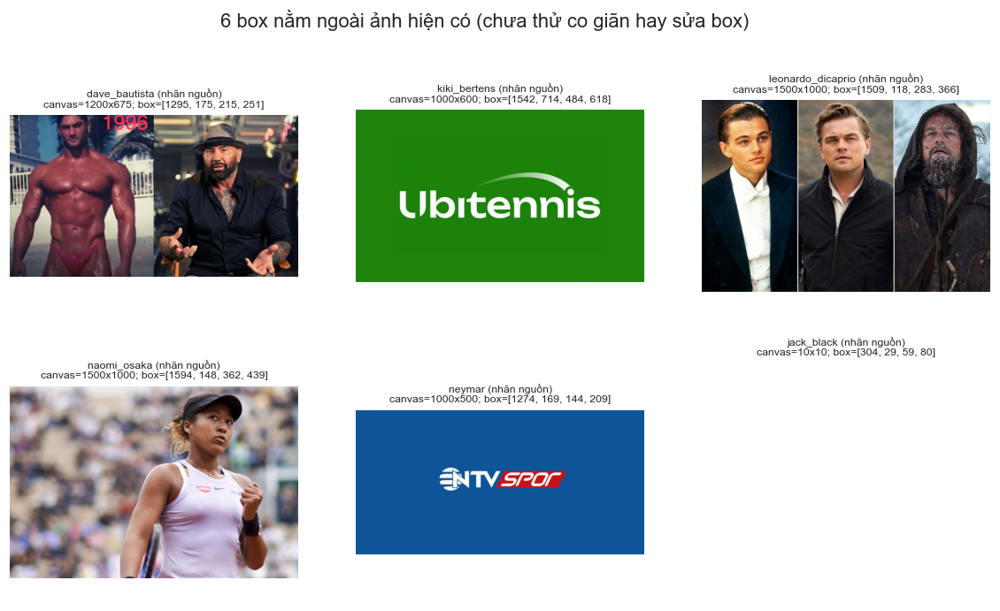

In [6]:
download_log=pd.DataFrame([json.loads(x) for x in (ROOT/'data/sources/rof/download_log.jsonl').read_text(encoding='utf-8').splitlines()])
source_expected=download_log.set_index('original_path').sha256.to_dict()
groups=[(path,g.to_dict('records')) for path,g in R[R.download_ok].groupby('original_path')]
def audit_source_group(item):
    path,rows=item;result=[]
    try:
        payload=(ROOT/path).read_bytes();source_sha=hashlib.sha256(payload).hexdigest()
        with Image.open(io.BytesIO(payload)) as im:
            im.load();W,H=im.size;orientation=int(im.getexif().get(274,1));rgb=im.convert('RGB')
        for r in rows:
            x,y,w,h=r['box'];x1,y1,x2,y2=max(0,x),max(0,y),min(W,x+w),min(H,y+h)
            valid_box=w>0 and h>0 and x2>x1 and y2>y1
            lm=np.asarray(r['landmarks'],dtype=float)
            finite=lm.shape==(5,2) and np.isfinite(lm).all()
            outside_canvas=int(((lm[:,0]<0)|(lm[:,0]>=W)|(lm[:,1]<0)|(lm[:,1]>=H)).sum()) if finite else -1
            outside_crop=int(((lm[:,0]<x1)|(lm[:,0]>x2)|(lm[:,1]<y1)|(lm[:,1]>y2)).sum()) if finite else -1
            record={'image_id':r['image_id'],'original_path':path,'source_width':W,'source_height':H,
                'source_sha256_now':source_sha,'source_sha_matches_log':source_sha==source_expected.get(path),
                'source_exif_orientation':orientation,'valid_box':valid_box,
                'annotation_area':w*h,'clipped_area':max(0,x2-x1)*max(0,y2-y1),
                'retained_fraction':max(0,x2-x1)*max(0,y2-y1)/(w*h) if w*h>0 else np.nan,
                'box_clipped_recomputed':[x1,y1,x2,y2]!=[x,y,x+w,y+h],
                'landmarks_finite':finite,'landmarks_outside_canvas':outside_canvas,
                'landmarks_outside_crop':outside_crop,'eyes_dx':float(lm[1,0]-lm[0,0]) if finite else np.nan,
                'crop_read_ok':False,'crop_pixel_matches_annotation':False,'crop_shape_matches':False,'error':''}
            if valid_box and r['crop_ok']:
                expected=np.asarray(rgb.crop((x1,y1,x2,y2)))
                with Image.open(ROOT/r['path']) as crop:actual=np.asarray(crop.convert('RGB'))
                record.update(crop_read_ok=True,crop_shape_matches=expected.shape==actual.shape,
                              crop_pixel_matches_annotation=bool(np.array_equal(expected,actual)))
            result.append(record)
    except Exception as e:
        result=[{'image_id':r['image_id'],'original_path':path,'crop_pixel_matches_annotation':False,
                 'source_sha_matches_log':False,'error':f'{type(e).__name__}: {e}'} for r in rows]
    return result
def audit_all_sources():
    result=[]
    with ThreadPoolExecutor(max_workers=WORKERS) as pool:
        for i,rows in enumerate(pool.map(audit_source_group,groups),1):
            result.extend(rows)
            if i%1000==0:print(f'Source/crop audit {i:,}/{len(groups):,}',flush=True)
    return pd.DataFrame(result)
box_fp=stat_fingerprint([ROOT/p for p,_ in groups]+[ROOT/p for p in R[R.crop_ok].path],
                        ['source-crop-landmark-v1',sha(ROOT/'data/sources/rof/acquired_records.json'),sha(TAB/'03_reparsed_annotations.csv')])
B_all=checkpoint('05_source_crop_audit',box_fp,audit_all_sources)
B=B_all[B_all.image_id.isin(set(R[R.crop_ok].image_id))].copy()
RB=R.merge(B_all,on=['image_id','original_path'],how='left',validate='one_to_one')
assert B_all.source_sha_matches_log.all(), 'Source bytes đổi so với log crawl'
assert B.crop_pixel_matches_annotation.all(), 'Crop không khớp annotation: cần điều tra trước bước tiếp'
display(B[['valid_box','crop_read_ok','crop_shape_matches','crop_pixel_matches_annotation','source_sha_matches_log']].sum().to_frame('pass_rows'))
display(Markdown(f'**{vn(len(B))} crop được dựng lại trong RAM và so pixel**, từ **{vn(len(groups))} ảnh gốc**; không ghi file mới. Cảnh báo về hình học được phân tích ở phần sau; khớp pixel không thay cho việc kiểm nội dung.'))
failed_box_rows=RB[RB.download_ok & ~RB.crop_ok].copy()
save(failed_box_rows,'05_downloaded_but_no_crop')
display(failed_box_rows[['image_id','identity','source_width','source_height','box','valid_box']])
display(Markdown(f"Các ảnh tải được có **{vn(len(B_all))} dòng annotation** nhưng chỉ có **{vn(len(B))} crop**: **{len(failed_box_rows)} box** nằm hoàn toàn ngoài ảnh nên đã bị loại từ lúc thu thập. Các dòng này không thuộc {vn(len(M))} ảnh của EDA nhưng vẫn được giữ trong bảng audit annotation."))
fig,axes=plt.subplots(2,3,figsize=(13,7))
for ax,r in zip(axes.flat,failed_box_rows.itertuples()):
    with Image.open(ROOT/r.original_path) as im:rgb=im.convert('RGB')
    ax.imshow(rgb);x,y,w,h=r.box
    ax.set_title(f'{r.identity} (nhãn nguồn)\ncanvas={rgb.width}x{rgb.height}; box={r.box}',fontsize=8)
    ax.set_xlim(0,rgb.width);ax.set_ylim(rgb.height,0);ax.axis('off')
fig.suptitle(f'{len(failed_box_rows)} box nằm ngoài ảnh hiện có (chưa thử co giãn hay sửa box)')
finish(fig,'06_annotations_outside_source')


### 6.1. Nhiều URL trả về cùng một file: phát hiện logo và truy tới crop
Khác URL vẫn có thể trả về cùng một file. Gom ảnh gốc theo SHA-256, xem ảnh đại diện, rồi chỉ áp kết luận cho các file có hash **giống hệt**. Ba file đã được xem trực tiếp là logo, không có mặt người; mọi crop sinh từ ba file này được đề xuất tạm giữ, kể cả khi entropy/tương phản chưa đủ thấp để bị gắn cờ "một màu".

Không phải file nguồn lặp nào cũng là ảnh giữ chỗ: một ảnh chụp hợp lệ có thể có nhiều URL hoặc chứa nhiều người. Kết luận "logo, không có mặt" đến từ việc xem ảnh, không phải từ detector. Raw và URL giữ nguyên, không crawl lại.

,source_sha256_now,URL_files,representative_path
19,00ec40e0e9264dfe3950b52b54a5004a7a597e431ba9ca286287d80b15219b23,4,data/raw/rof_originals/88f3e868d07b83f643a79f3ab8fb1377081739998345c1b3...
3774,9a18a8cb0080b223da4a37af484664ce67005f9cea2f7b3c50b76e80382c7929,2,data/raw/rof_originals/7d4d8dfd8757e85d1d31dc44973ae27a976a31cbfa66d23e...
5452,df5995146157da1d66e24e59c08b672895678c1c3796d0ed76a2cec682309c23,30,data/raw/rof_originals/09953f07f3953d2b6f49b1ea00b8562775795f6e4e06b93e...


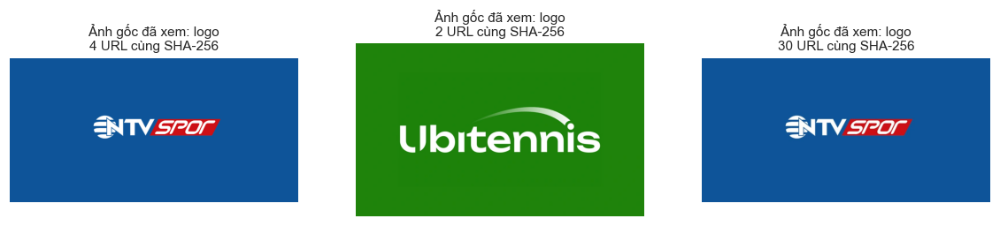

**3 file logo đã xác minh** ảnh hưởng tới **34 crop**. Truy theo nguồn gốc (ảnh gốc → crop) bắt được cả những crop không bị gắn cờ "một màu". Các file/URL lặp vẫn được ghi vào ràng buộc chống rò rỉ, không dùng để gộp người.

In [7]:
source_files=B_all.drop_duplicates('original_path').copy()
source_reuse=source_files.groupby('source_sha256_now').agg(URL_files=('original_path','size'),
    representative_path=('original_path','first')).reset_index()
source_reuse=source_reuse[source_reuse.URL_files.gt(1)]
save(source_reuse,'05_reused_source_files');display(source_reuse)
asset_path=QA/'verified_source_assets.csv';assets=read_table(asset_path)
assert assets.source_sha256.is_unique
for r in assets.itertuples():
    assert sha(ROOT/r.representative_path)==r.source_sha256
    assert r.finding=='logo_asset_no_face'
placeholder_ids=set(B_all[B_all.source_sha256_now.isin(set(assets.source_sha256))].image_id)&set(M.image_id)
source_asset_descendants=R[R.image_id.isin(placeholder_ids)].merge(
    B_all[['image_id','source_sha256_now']],on='image_id',validate='one_to_one')
save(source_asset_descendants,'05_verified_placeholder_descendants')
fig,axes=plt.subplots(1,len(assets),figsize=(13,4))
for ax,r in zip(axes,assets.itertuples()):
    with Image.open(ROOT/r.representative_path) as im:ax.imshow(im.convert('RGB'))
    count=source_files.source_sha256_now.eq(r.source_sha256).sum()
    ax.set_title(f'Ảnh gốc đã xem: logo\n{count} URL cùng SHA-256',fontsize=10);ax.axis('off')
finish(fig,'06_reused_logo_sources')
display(Markdown(f"**{len(assets)} file logo đã xác minh** ảnh hưởng tới **{len(placeholder_ids)} crop**. Truy theo nguồn gốc (ảnh gốc → crop) bắt được cả những crop không bị gắn cờ \"một màu\". Các file/URL lặp vẫn được ghi vào ràng buộc chống rò rỉ, không dùng để gộp người."))

## 7. Cách đọc contact sheet và log review
Tên hiển thị trên hình là **nhãn của nguồn**, không phải kết quả nhận diện. Việc xem ảnh có thể xác nhận ảnh nền phẳng, crop chỉ thấy thân hoặc ảnh sọc, cùng một ảnh bị nén lại, hoặc box vượt biên; không dùng để đoán người trong ảnh là ai.

Mỗi hình có số thứ tự truy về CSV. Toàn bộ trang được xuất vào `contact_sheets/`; notebook chỉ hiển thị trang tiêu biểu. Ảnh nhỏ được phóng bằng nearest-neighbor để thấy rõ pixel; đây chỉ là hình để xem, raw không đổi. Nhận xét từng trường hợp lưu trong `case_review_decisions.csv`.

In [8]:
FONT_PATH=Path('C:/Windows/Fonts/arial.ttf')
def font(size):return ImageFont.truetype(str(FONT_PATH),size) if FONT_PATH.exists() else ImageFont.load_default()
def fit_image(im,size,bg='white',nearest=False):
    im=im.convert('RGB').copy();scale=min(size[0]/im.width,size[1]/im.height)
    im=im.resize((max(1,round(im.width*scale)),max(1,round(im.height*scale))),Image.Resampling.NEAREST if nearest else Image.Resampling.LANCZOS)
    canvas=Image.new('RGB',size,bg);canvas.paste(im,((size[0]-im.width)//2,(size[1]-im.height)//2));return canvas
def rgb_open(path):
    with Image.open(ROOT/path) as im:return ImageOps.exif_transpose(im).convert('RGB')
def show_sheet(path):display(Image.open(path))
def raw_sheets(frame,prefix,cols=6,per_page=24,nearest=False):
    pages=[];mapping=[];frame=frame.reset_index(drop=True)
    for start in range(0,len(frame),per_page):
        sub=frame.iloc[start:start+per_page];rows=math.ceil(len(sub)/cols);cw,ch=245,260
        page=Image.new('RGB',(cols*cw,rows*ch+55),'white');draw=ImageDraw.Draw(page)
        draw.text((12,10),f'{prefix} | {start+1}-{start+len(sub)}/{len(frame)} | source labels only',fill='black',font=font(21))
        for j,r in enumerate(sub.itertuples()):
            x=(j%cols)*cw;y=(j//cols)*ch+55
            page.paste(fit_image(rgb_open(r.path),(cw-8,200),nearest=nearest),(x+4,y+50))
            label=f'{start+j+1} {r.source}: {r.identity}\n{r.condition} | {r.image_id[-8:]}'
            draw.text((x+4,y+2),label,fill='black',font=font(13))
            mapping.append({'image_id':r.image_id,'sheet':f'{prefix}_{start//per_page+1:02d}.jpg','sheet_position':j+1})
        p=SHEETS/f'{prefix}_{start//per_page+1:02d}.jpg';page.save(p,quality=94);pages.append(p)
    return pages,pd.DataFrame(mapping)

def context_sheets(ids,prefix,per_page=6):
    pages=[];mapping=[]
    for start in range(0,len(ids),per_page):
        sub=ids[start:start+per_page];cw,ch=1160,280
        page=Image.new('RGB',(cw,len(sub)*ch+45),'white');draw=ImageDraw.Draw(page)
        draw.text((10,8),f'{prefix}: cyan=author boxes; red=target; source coordinate system',fill='black',font=font(19))
        for j,image_id in enumerate(sub):
            r=RB.set_index('image_id').loc[image_id]
            with Image.open(ROOT/r.original_path) as src:im=src.convert('RGB')
            scale=min(700/im.width,220/im.height);thumb=im.resize((max(1,round(im.width*scale)),max(1,round(im.height*scale))))
            overlay=ImageDraw.Draw(thumb)
            siblings=R[R.original_path==r.original_path]
            for sib in siblings.itertuples():
                x,y,w,h=sib.box;color='red' if sib.image_id==image_id else '#00b7c7'
                overlay.rectangle([x*scale,y*scale,(x+w)*scale,(y+h)*scale],outline=color,width=3)
                overlay.text((max(0,x*scale),max(0,y*scale-15)),str(sib.face_index),fill=color,font=font(14))
            y0=45+j*ch
            draw.text((10,y0),f'{start+j+1} {image_id} | source label={r.identity} / {r.source_condition}',fill='black',font=font(16))
            page.paste(fit_image(thumb,(700,230)),(8,y0+32))
            page.paste(fit_image(rgb_open(r.path),(230,230)),(725,y0+32))
            draw.text((965,y0+50),f'entry boxes: {r.faces_in_entry}\nkeep: {r.retained_fraction:.3f}\nmin crop: {min(rgb_open(r.path).size)}',fill='black',font=font(14))
            mapping.append({'image_id':image_id,'sheet':f'{prefix}_{start//per_page+1:02d}.jpg','sheet_position':j+1})
        p=SHEETS/f'{prefix}_{start//per_page+1:02d}.jpg';page.save(p,quality=93);pages.append(p)
    return pages,pd.DataFrame(mapping)

## 8. Crop gần như một màu và crop quá nhỏ
Kiểm lại các cờ của EDA bằng ảnh gốc. Tạm giữ crop gần như không có thông tin là quyết định về chất lượng dữ liệu, không phải kết luận về người trong ảnh. Crop có cạnh dưới 20 px không đạt `min_face_size` của MTCNN hiện tại; pipeline khác có thể vẫn xử lý được.

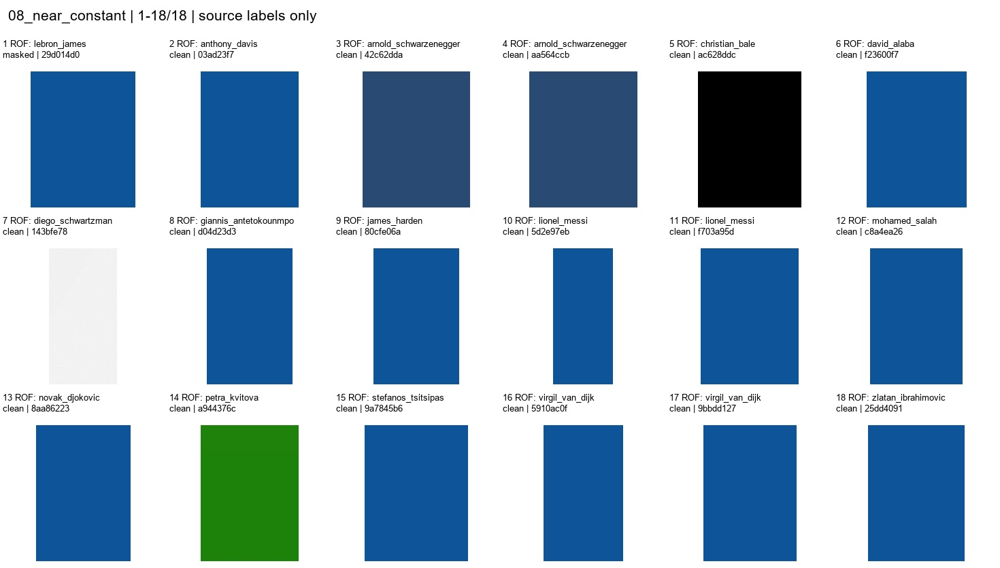

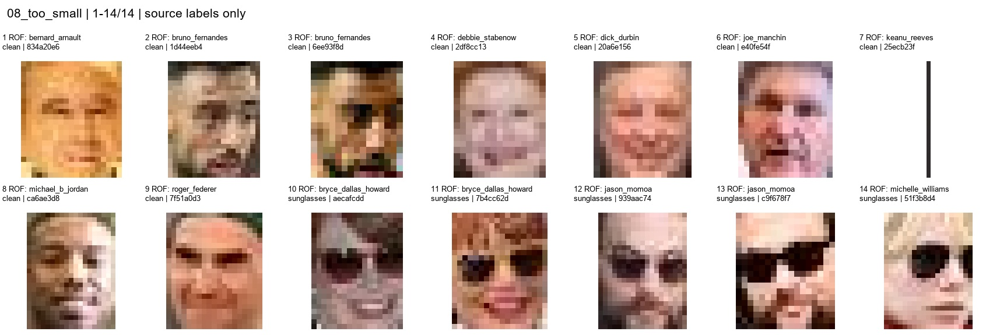

Có **18 crop gần như một màu** và **14 crop có cạnh < 20 px** (đếm theo ảnh, không cộng trùng). Không phóng to rồi coi như đã sửa. Ảnh gốc vẫn được giữ để nhóm quyết định sửa annotation ở bước riêng hay bỏ crop này khỏi đánh giá.

In [9]:
flat=M[(M.contrast<1)&((M.gray_p95-M.gray_p05)<=2)].copy()
tiny=M[M.min_side<20].copy()
flat_pages,flat_map=raw_sheets(flat,'08_near_constant',cols=6)
tiny_pages,tiny_map=raw_sheets(tiny,'08_too_small',cols=7,nearest=True)
save(flat,'06_near_constant');save(tiny,'06_too_small');save(pd.concat([flat_map,tiny_map]),'06_review_page_map')
show_sheet(flat_pages[0]);show_sheet(tiny_pages[0])
display(Markdown(f'Có **{len(flat)} crop gần như một màu** và **{len(tiny)} crop có cạnh < 20 px** (đếm theo ảnh, không cộng trùng). Không phóng to rồi coi như đã sửa. Ảnh gốc vẫn được giữ để nhóm quyết định sửa annotation ở bước riêng hay bỏ crop này khỏi đánh giá.'))

## 9. Trùng tuyệt đối: chứng minh trùng, không đoán nhãn đúng
Hash bytes và hash pixel có thể cho cùng một nhóm; ta dùng nhóm theo hash pixel. Cùng pixel nhưng khác nhãn là mâu thuẫn đã được chứng minh; không suy nhãn đúng từ URL hay độ giống khuôn mặt. Với nhóm cùng nhãn, sau khi chốt protocol có thể giữ một bản đại diện để tránh đếm lặp khi đánh giá; raw vẫn giữ cả hai.

,group_id,image_id,source,identity,condition,group_size,labels_in_group,conditions_in_group,cross_label,pixel_sha256
0,EXACT_5fcbec184ba29684,ROF_553a90f4d72921b90b74,ROF,anthony_davis,sunglasses,2,1,1,False,5fcbec184ba29684d6eb07165e65a033c4e0bd54dbbf6c1d0abc5c66dfe136a7
1,EXACT_5fcbec184ba29684,ROF_10b7c931ee5679a82fb5,ROF,anthony_davis,sunglasses,2,1,1,False,5fcbec184ba29684d6eb07165e65a033c4e0bd54dbbf6c1d0abc5c66dfe136a7
2,EXACT_63a9d46890c9c93e,ROF_fb651ba2e211d193b121,ROF,paul_bettany,clean,2,1,2,False,63a9d46890c9c93eda40eff7b913500684968b6ddf2a2fc4d333fe6b3b2bdf57
3,EXACT_63a9d46890c9c93e,ROF_63369ac986dec9aa94a2,ROF,paul_bettany,sunglasses,2,1,2,False,63a9d46890c9c93eda40eff7b913500684968b6ddf2a2fc4d333fe6b3b2bdf57
4,EXACT_964655eacf48765c,ROF_eb631d9edcca6eb293e3,ROF,charles_leclerc,clean,2,1,2,False,964655eacf48765ccc78fa8dc14cb419a9af83a6039d5f8b1470e06e1c5f6eeb
5,EXACT_964655eacf48765c,ROF_cf1067b3e5a8645e3741,ROF,charles_leclerc,sunglasses,2,1,2,False,964655eacf48765ccc78fa8dc14cb419a9af83a6039d5f8b1470e06e1c5f6eeb
6,EXACT_d9962f747b354bca,ROF_dee2751666151a88c536,ROF,dave_bautista,clean,2,1,2,False,d9962f747b354bca75a4bdd6efad6d67e0e407ae538250608fb0b18910b899cf
7,EXACT_d9962f747b354bca,ROF_90610b1f1dd4b4c78596,ROF,dave_bautista,sunglasses,2,1,2,False,d9962f747b354bca75a4bdd6efad6d67e0e407ae538250608fb0b18910b899cf
8,EXACT_f046357aa7d6b84b,ROF_ae79cbd3ea0ef65afcf7,ROF,kylian_mbappe,masked,2,2,1,True,f046357aa7d6b84bb306bc55d94ab84aa4870db44f956d7cacec202f35b68893
9,EXACT_f046357aa7d6b84b,ROF_dc11e620b5e29ef66124,ROF,neymar,masked,2,2,1,True,f046357aa7d6b84bb306bc55d94ab84aa4870db44f956d7cacec202f35b68893


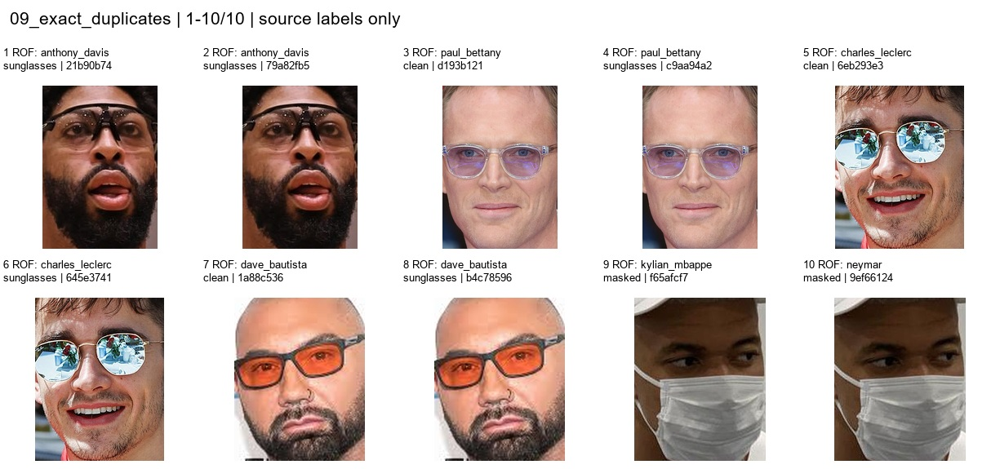

**5 nhóm / 10 ảnh** trùng pixel, trong đó **1 nhóm / 2 ảnh khác nhãn**. Cả hai ảnh mâu thuẫn được đề xuất tạm giữ, chưa sửa nhãn nào. Bản đại diện của nhóm cùng nhãn được chọn theo thứ tự `image_id` để tái lập được, không dựa vào chất lượng ảnh.

In [10]:
exact_rows=[]
for h,g in M.groupby('pixel_sha256'):
    if len(g)<2:continue
    key='EXACT_'+h[:16]
    for r in g.itertuples():exact_rows.append({'group_id':key,'image_id':r.image_id,'source':r.source,
        'identity':r.identity,'condition':r.condition,'group_size':len(g),
        'labels_in_group':g.canonical_identity.nunique(),'conditions_in_group':g.condition.nunique(),
        'cross_label':g.canonical_identity.nunique()>1,'pixel_sha256':h})
exact=save(pd.DataFrame(exact_rows),'07_exact_members')
display(exact)
exact_pages,exact_map=raw_sheets(lookup.loc[exact.image_id].reset_index(drop=True),'09_exact_duplicates',cols=5)
show_sheet(exact_pages[0]);save(exact_map,'07_exact_page_map')
conflict_ids=set(exact[exact.cross_label].image_id)
display(Markdown(f'**{exact.group_id.nunique()} nhóm / {len(exact)} ảnh** trùng pixel, trong đó **{exact[exact.cross_label].group_id.nunique()} nhóm / {len(conflict_ids)} ảnh khác nhãn**. Cả hai ảnh mâu thuẫn được đề xuất tạm giữ, chưa sửa nhãn nào. Bản đại diện của nhóm cùng nhãn được chọn theo thứ tự `image_id` để tái lập được, không dựa vào chất lượng ảnh.'))

## 10. Gần trùng: tách trùng thật và báo nhầm
Đầu vào là toàn bộ 488 cặp pHash từ EDA. Tính thêm khoảng cách Hamming, sai khác RGB trung bình (MAE) sau khi resize về 224 và SSIM toàn khung (Gaussian 11×11, sigma 1,5). Đây là phép so **cấu trúc ảnh**, không phải so embedding danh tính; ngưỡng chỉ dùng để sắp xếp hàng đợi review.

Ảnh gần như một màu có pHash gần nhau dù không chứa mặt, nên được tách riêng. Với hai ảnh khác tỷ lệ khung, SSIM sau khi kéo về hình vuông chỉ mang tính tham khảo; phải xem ảnh gốc. SSIM cao hay MAE thấp cũng không chứng minh là cùng người.

pairs
source_a same_label pixel_equal has_flat       
DigiFace False      False       False       228
         True       False       False        18
ROF      False      False       False         6
                                True        117
                    True        False         1
         True       False       False       111
                                True          3
                    True        False         4

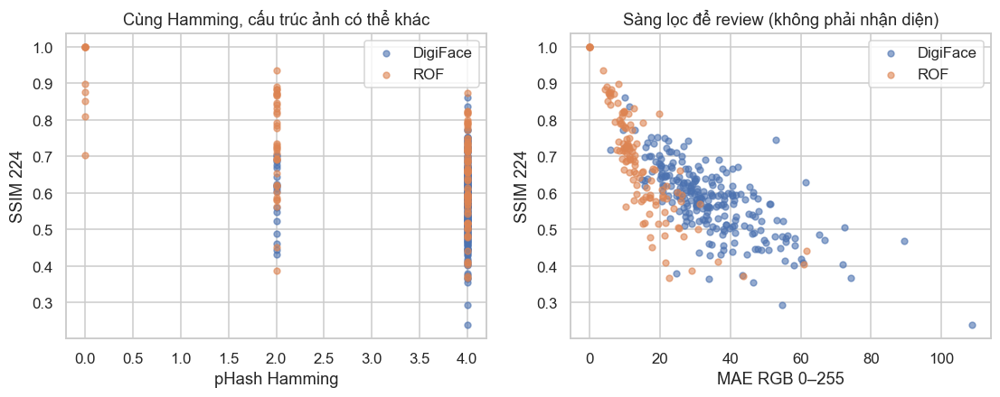

In [11]:
def ssim_gray(a,b):
    a=cv2.cvtColor(a,cv2.COLOR_RGB2GRAY).astype(float);b=cv2.cvtColor(b,cv2.COLOR_RGB2GRAY).astype(float)
    mu_a=cv2.GaussianBlur(a,(11,11),1.5);mu_b=cv2.GaussianBlur(b,(11,11),1.5)
    va=cv2.GaussianBlur(a*a,(11,11),1.5)-mu_a*mu_a
    vb=cv2.GaussianBlur(b*b,(11,11),1.5)-mu_b*mu_b
    cov=cv2.GaussianBlur(a*b,(11,11),1.5)-mu_a*mu_b
    score=((2*mu_a*mu_b+6.5025)*(2*cov+58.5225))/((mu_a*mu_a+mu_b*mu_b+6.5025)*(va+vb+58.5225))
    return float(score[5:-5,5:-5].mean())
pair_stats=[]
for i,r in enumerate(N.itertuples()):
    a=lookup.loc[r.image_id_a];b=lookup.loc[r.image_id_b]
    aa=np.asarray(rgb_open(a.path).resize((224,224),Image.Resampling.BILINEAR))
    bb=np.asarray(rgb_open(b.path).resize((224,224),Image.Resampling.BILINEAR))
    hamming=(int(a.phash64,16)^int(b.phash64,16)).bit_count()
    assert hamming==r.distance
    pair_stats.append({'pair_id':f'PAIR_{i+1:04d}','image_id_a':a.image_id,'image_id_b':b.image_id,
        'source_a':a.source,'source_b':b.source,'identity_a':a.identity,'identity_b':b.identity,
        'condition_a':a.condition,'condition_b':b.condition,'hamming':hamming,
        'same_label':a.canonical_identity==b.canonical_identity,'pixel_equal':a.pixel_sha256==b.pixel_sha256,
        'has_flat':a.image_id in set(flat.image_id) or b.image_id in set(flat.image_id),
        'aspect_ratio_delta':abs(a.aspect_ratio-b.aspect_ratio),
        'mae_rgb_224':float(np.abs(aa.astype(float)-bb.astype(float)).mean()),'ssim_224':ssim_gray(aa,bb)})
P=save(pd.DataFrame(pair_stats),'08_near_pair_metrics')
P['screen_near_pixel']=P.ssim_224.ge(.98)&P.mae_rgb_224.le(3)&P.aspect_ratio_delta.le(.02)&~P.has_flat&~P.pixel_equal
save(P,'08_near_pair_metrics')
display(P.groupby(['source_a','same_label','pixel_equal','has_flat']).size().rename('pairs').to_frame())
fig,axes=plt.subplots(1,2,figsize=(12,4))
for source,g in P[~P.has_flat].groupby('source_a'):
    axes[0].scatter(g.hamming,g.ssim_224,s=20,alpha=.6,label=source)
    axes[1].scatter(g.mae_rgb_224,g.ssim_224,s=20,alpha=.6,label=source)
axes[0].set(xlabel='pHash Hamming',ylabel='SSIM 224',title='Cùng Hamming, cấu trúc ảnh có thể khác')
axes[1].set(xlabel='MAE RGB 0–255',ylabel='SSIM 224',title='Sàng lọc để review (không phải nhận diện)')
for ax in axes:ax.legend()
finish(fig,'10_near_duplicate_screen')

### 10.1. Xuất toàn bộ cặp cần xem
Các cặp có ảnh nền phẳng đã được giải thích ở phần 8 nên không xuất lại 120 cặp đó. Các cặp còn lại, kể cả cặp trùng tuyệt đối, được xuất đủ; mỗi ô có `pair_id` và hai nhãn nguồn. Trang nào chưa xem thì không được đánh dấu là đã xem.

,pairs
sheet,
10_near_pairs_01.jpg,12
10_near_pairs_02.jpg,12
10_near_pairs_03.jpg,12
10_near_pairs_04.jpg,12
10_near_pairs_05.jpg,12
10_near_pairs_06.jpg,12
10_near_pairs_07.jpg,12
10_near_pairs_08.jpg,12
10_near_pairs_09.jpg,12


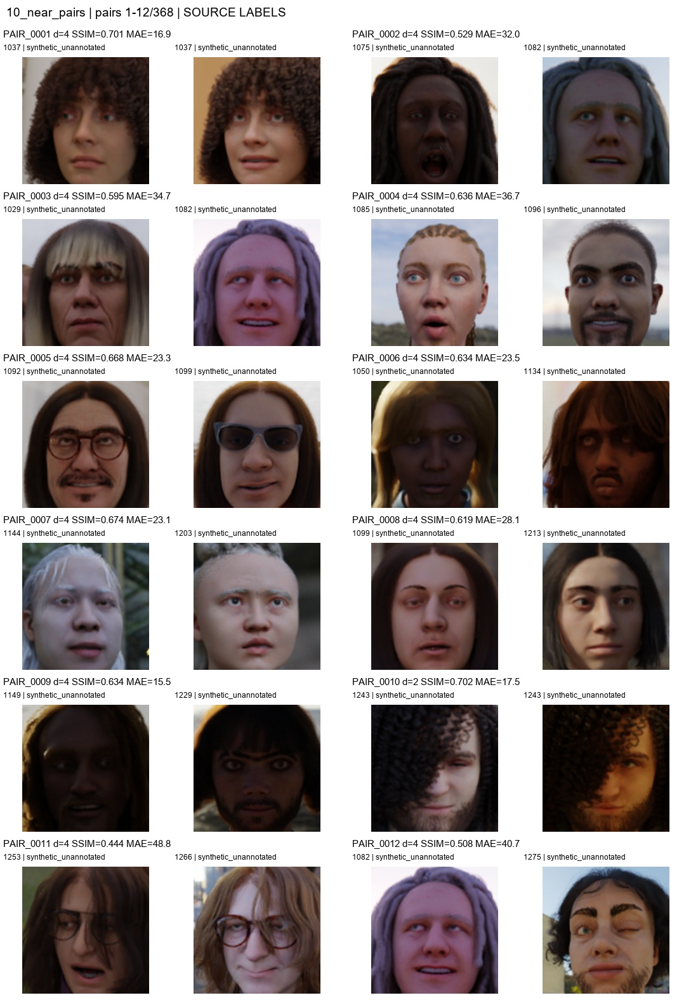

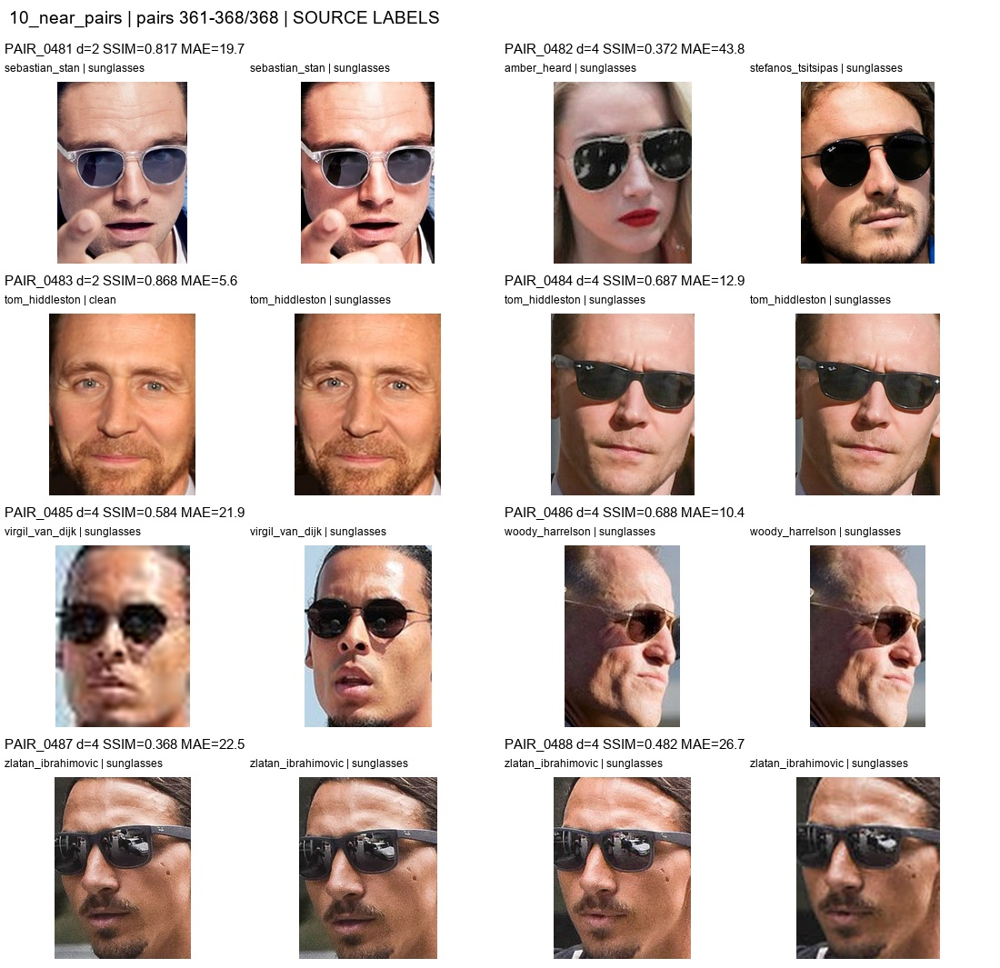

In [12]:
def pair_sheets(frame,prefix,per_page=12):
    pages=[];mapping=[];frame=frame.reset_index(drop=True)
    for start in range(0,len(frame),per_page):
        sub=frame.iloc[start:start+per_page];cw,ch=550,255;cols=2;rows=math.ceil(len(sub)/cols)
        page=Image.new('RGB',(cols*cw,rows*ch+45),'white');draw=ImageDraw.Draw(page)
        draw.text((10,8),f'{prefix} | pairs {start+1}-{start+len(sub)}/{len(frame)} | SOURCE LABELS',fill='black',font=font(19))
        for j,r in enumerate(sub.itertuples()):
            x=(j%cols)*cw;y=(j//cols)*ch+45
            draw.text((x+5,y),f'{r.pair_id} d={r.hamming} SSIM={r.ssim_224:.3f} MAE={r.mae_rgb_224:.1f}',fill='black',font=font(15))
            for k,image_id in enumerate([r.image_id_a,r.image_id_b]):
                a=lookup.loc[image_id]
                draw.text((x+5+k*270,y+23),f'{a.identity[:30]} | {a.condition}',fill='black',font=font(12))
                page.paste(fit_image(rgb_open(a.path),(260,200)),(x+5+k*270,y+45))
            mapping.append({'pair_id':r.pair_id,'sheet':f'{prefix}_{start//per_page+1:02d}.jpg','sheet_position':j+1})
        p=SHEETS/f'{prefix}_{start//per_page+1:02d}.jpg';page.save(p,quality=95);pages.append(p)
    return pages,pd.DataFrame(mapping)
pair_pages,pair_map=pair_sheets(P[~P.has_flat].sort_values(['source_a','pair_id']),'10_near_pairs')
save(pair_map,'08_pair_page_map');display(pair_map.groupby('sheet').size().rename('pairs').to_frame())
show_sheet(pair_pages[0]);show_sheet(pair_pages[-1])

## 11. Bounding box của nguồn: bị cắt biên và landmark
`retained_fraction` là phần diện tích box nằm trong ảnh chia cho diện tích box gốc. Đây không phải tỷ lệ bị che hay độ chính xác của detector. Landmark nằm ngoài box/ảnh là dấu hiệu lỗi tọa độ hoặc annotation; landmark là dự đoán của nguồn nên không dùng để tự sửa ảnh.

,n,clipped,min_keep,landmark_outside_canvas,landmark_outside_crop
source_condition,,,,,
masked,264,1,0.152893,1,1
neutral,4356,56,0.045714,9,9
sunglasses,2091,26,0.258333,6,9


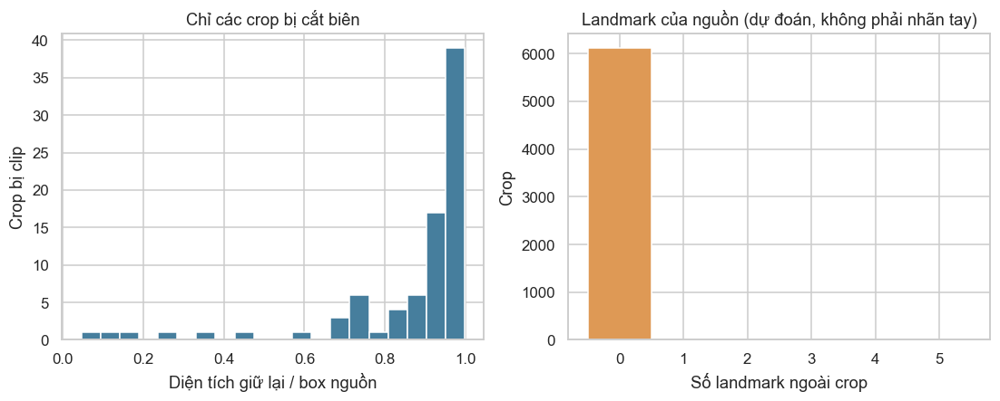

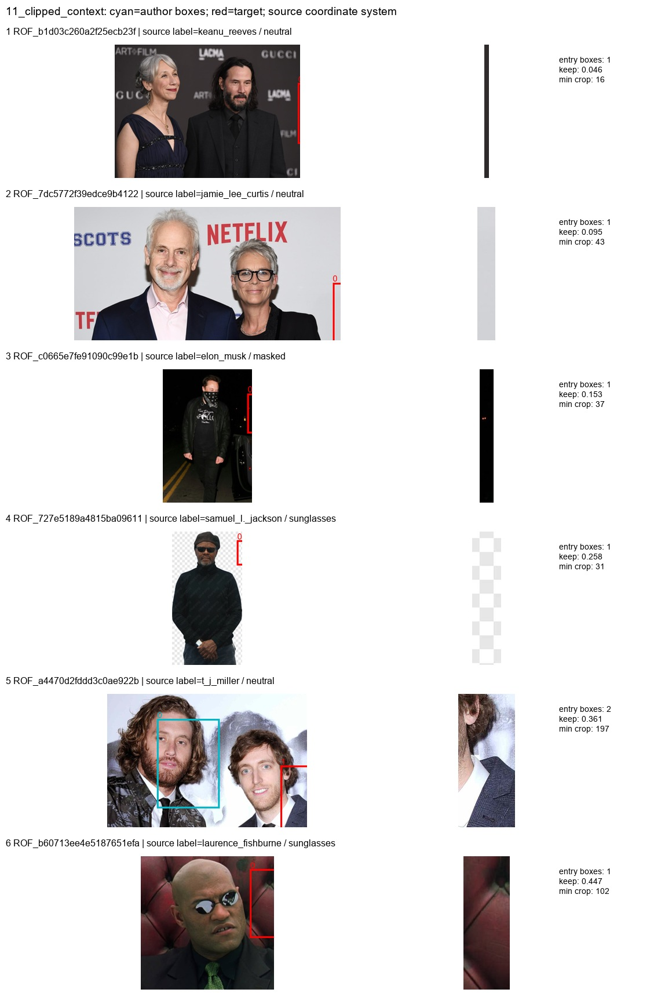

**83 crop bị cắt biên**; crop giữ ít nhất **4,57%** diện tích box. Chưa loại theo một ngưỡng diện tích tùy ý: cần xem cả ảnh gốc và crop trước khi đề xuất sửa box; bước này không ghi box mới.

In [13]:
geometry=RB[RB.crop_ok].copy()
geometry['lost_fraction']=1-geometry.retained_fraction
clip=geometry[geometry.box_clipped_recomputed].sort_values(['retained_fraction','image_id'])
save(clip,'09_clipped_boxes');save(geometry[geometry.landmarks_outside_canvas.gt(0)|geometry.landmarks_outside_crop.gt(0)],'09_landmark_alerts')
display(geometry.groupby('source_condition').agg(n=('image_id','size'),clipped=('box_clipped_recomputed','sum'),
    min_keep=('retained_fraction','min'),landmark_outside_canvas=('landmarks_outside_canvas',lambda x:int(x.gt(0).sum())),
    landmark_outside_crop=('landmarks_outside_crop',lambda x:int(x.gt(0).sum()))))
fig,axes=plt.subplots(1,2,figsize=(12,4))
axes[0].hist(clip.retained_fraction,bins=20,color='#467e9d');axes[0].set(xlabel='Diện tích giữ lại / box nguồn',ylabel='Crop bị clip',title='Chỉ các crop bị cắt biên')
axes[1].hist(geometry.landmarks_outside_crop,bins=np.arange(-.5,6.5),color='#de9955');axes[1].set(xlabel='Số landmark ngoài crop',ylabel='Crop',title='Landmark của nguồn (dự đoán, không phải nhãn tay)')
finish(fig,'11_source_box_geometry')
clip_pages,clip_map=context_sheets(clip.image_id.tolist(),'11_clipped_context')
save(clip_map,'09_clip_page_map');show_sheet(clip_pages[0])
display(Markdown(f'**{len(clip)} crop bị cắt biên**; crop giữ ít nhất **{pct(clip.retained_fraction.min())}** diện tích box. Chưa loại theo một ngưỡng diện tích tùy ý: cần xem cả ảnh gốc và crop trước khi đề xuất sửa box; bước này không ghi box mới.'))

## 12. Nhiều box dưới một nhãn: nguy cơ gán nhầm người
Code tải của tác giả lưu **mọi** khuôn mặt trong một ảnh vào cùng thư mục nhãn, và bộ crawl cũng giữ nguyên như vậy. Vì thế không thể mặc định `face_index=0` là đúng người, và detector tìm thấy một mặt trong crop cũng không có nghĩa nhãn thư mục đúng.

Đếm mọi entry có nhiều box, trước và sau khi crawl; xem các ví dụ nhiều box, crop vào thân/mặt phụ và các ca EDA đã cảnh báo. Khi chưa biết box nào là của người được gán nhãn thì đề xuất tạm giữ để nhóm đối chiếu, không tự chọn mặt lớn nhất.

,annotation_rows,multi_rows,acquired,multi_acquired
source_condition,,,,
masked,515,90,264,59
neutral,6659,546,4356,344
sunglasses,2963,431,2091,320


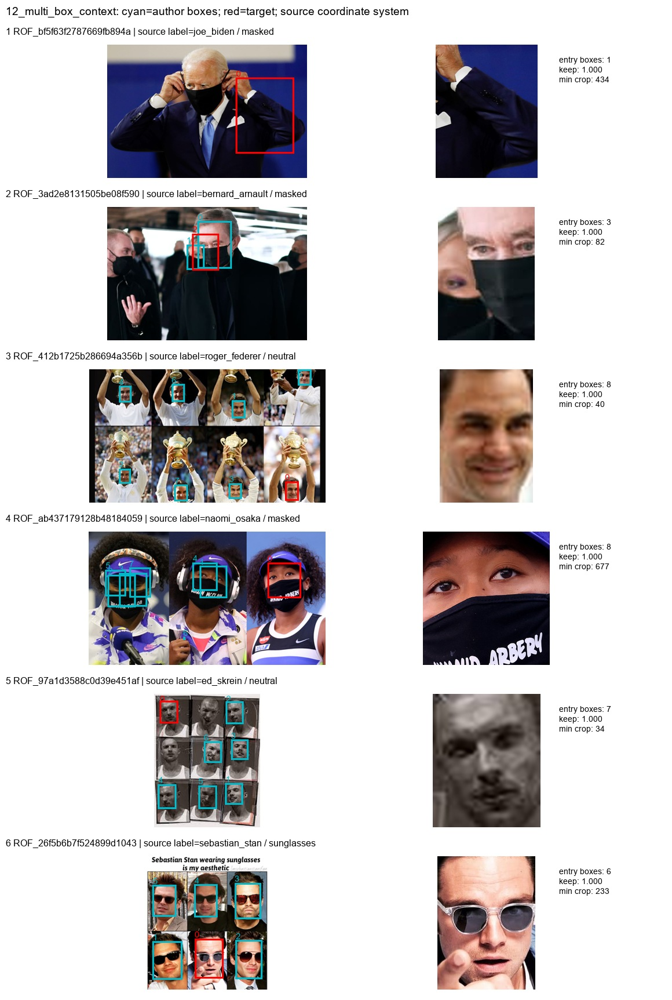

**1.067 dòng annotation** thuộc entry có nhiều box; **723 crop** trong số đó đã tải được. Cả nhóm này được đề xuất tạm giữ cho tới khi xác định được box nào thuộc người được gán nhãn; không có nghĩa tất cả đều sai nhãn. Hình minh họa chỉ gồm 26 crop chọn có chủ đích và theo seed.

In [14]:
multi_all=R[R.faces_in_entry>1].copy();multi=multi_all[multi_all.crop_ok].copy()
save(multi_all,'10_multiple_author_boxes_all');save(multi,'10_multiple_author_boxes_acquired')
multi_summary=R.groupby('source_condition').agg(annotation_rows=('image_id','size'),
    multi_rows=('faces_in_entry',lambda x:int(x.gt(1).sum())),acquired=('crop_ok','sum'))
multi_summary['multi_acquired']=multi.groupby('source_condition').size()
save(multi_summary.reset_index(),'10_multi_summary');display(multi_summary)
# Một entry đại diện; không để nhiều crop cùng scene chiếm hết mẫu minh họa.
multi_scene=multi.drop_duplicates(['annotation_file','annotation_key']).copy()
multi_scene['sort_key']=multi_scene.image_id.map(lambda x:hashlib.sha256((str(SEED)+x).encode()).hexdigest())
chosen=pd.concat([multi_scene.sort_values(['faces_in_entry','image_id'],ascending=[False,True]).head(8),
                   multi_scene.sort_values('sort_key').head(16)]).drop_duplicates('image_id')
old_reviews=read_table(EDA/'rof_visual_qa_manual_review.csv')
known=old_reviews[old_reviews['index'].isin([26,27])].image_id.tolist()
multi_ids=list(dict.fromkeys(known+chosen.image_id.tolist()))
multi_pages,multi_map=context_sheets(multi_ids,'12_multi_box_context');save(multi_map,'10_multi_page_map')
show_sheet(multi_pages[0]);display(Markdown(f'**{vn(len(multi_all))} dòng annotation** thuộc entry có nhiều box; **{vn(len(multi))} crop** trong số đó đã tải được. Cả nhóm này được đề xuất tạm giữ cho tới khi xác định được box nào thuộc người được gán nhãn; không có nghĩa tất cả đều sai nhãn. Hình minh họa chỉ gồm {len(multi_ids)} crop chọn có chủ đích và theo seed.'))

### 12.1. Box chồng lên nhau, ảnh ghép và nhiều vùng mặt
Xem ảnh cho thấy nhiều box có thể là các dự đoán chồng lên cùng một khuôn mặt, ảnh ghép (collage), hoặc nhiều người trong cảnh. Ta gom các box chồng nhau (IoU ≥ 0,3 hoặc phần giao / diện tích box nhỏ hơn ≥ 0,75) để mô tả mức chồng lấn. Ngưỡng này chỉ để mô tả hình học, không chứng minh số người và không dùng để gỡ cờ tạm giữ. Kịch bản B ở phần 19 vẫn tạm giữ toàn bộ nhóm nhiều box như một lựa chọn thận trọng.

In [15]:
overlap_rows=[]
for (file,key),g in A[A.faces_in_entry.gt(1)].groupby(['annotation_file','annotation_key']):
    rows=g.to_dict('records');parents=list(range(len(rows)))
    def find_local(i):
        while parents[i]!=i:i=parents[i]
        return i
    links=0
    for i in range(len(rows)):
        for j in range(i):
            x,y,w,h=rows[i]['box'];a,b,c,d=rows[j]['box']
            inter=max(0,min(x+w,a+c)-max(x,a))*max(0,min(y+h,b+d)-max(y,b))
            union=w*h+c*d-inter
            ov_iou=inter/max(1,union);ov_small=inter/max(1,min(w*h,c*d))
            if ov_iou>=.3 or ov_small>=.75:
                parents[find_local(i)]=find_local(j);links+=1
    clusters=len({find_local(i) for i in range(len(rows))})
    overlap_rows.append({'annotation_file':file,'annotation_key':key,'boxes':len(rows),
        'spatial_clusters':clusters,'overlap_links':links,
        'geometry_pattern':'one_overlapping_region' if clusters==1 else 'multiple_spatial_regions',
        'identity_verified':False})
overlap_audit=save(pd.DataFrame(overlap_rows),'10_box_overlap_structure')
display(overlap_audit.groupby('geometry_pattern').agg(entries=('annotation_key','size'),boxes=('boxes','sum')))
display(Markdown('Một vùng box chồng nhau vẫn có thể là sai người; nhiều vùng có thể là ảnh ghép của cùng một người hoặc nhiều người khác nhau. Không đổi quy tắc thành "chọn box đầu tiên/lớn nhất". Muốn giảm số ảnh tạm giữ thì người duyệt phải nối từng box với ảnh tham chiếu tin cậy.'))

,entries,boxes
geometry_pattern,,
multiple_spatial_regions,369,869
one_overlapping_region,89,198


Một vùng box chồng nhau vẫn có thể là sai người; nhiều vùng có thể là ảnh ghép của cùng một người hoặc nhiều người khác nhau. Không đổi quy tắc thành "chọn box đầu tiên/lớn nhất". Muốn giảm số ảnh tạm giữ thì người duyệt phải nối từng box với ảnh tham chiếu tin cậy.

## 13. Crop của nguồn và bbox của detector là hai thứ khác nhau
Trong audit MTCNN ở EDA, nhiều crop sát mặt có bbox vượt khung; không coi tất cả là lỗi annotation. Ta đo phần diện tích bbox detector thực sự nằm trong ảnh, landmark của detector nằm ngoài khung, và so với ảnh gốc.

Với 600 ảnh gốc đã audit, tọa độ MTCNN trên ảnh thu nhỏ được quy đổi về kích thước gốc theo từng trục (chỉ khi EXIF = 1; ảnh bị xoay cần phép biến đổi riêng). "Tâm detection nằm trong box của tác giả" chỉ là quan hệ vị trí, **chưa xác minh danh tính**. IoU thấp có thể do box của nguồn bao cả đầu còn detector chỉ lấy vùng mặt.

In [16]:
crop_det=D[D.source.ne('ROF_scene')].copy()
scenes=D[D.source.eq('ROF_scene')].drop_duplicates('original_path').copy()
scene_lookup=scenes.set_index('original_path')
def parse_list(x):return ast.literal_eval(x) if isinstance(x,str) else x
def iou(a,b):
    x1,y1=max(a[0],b[0]),max(a[1],b[1]);x2,y2=min(a[2],b[2]),min(a[3],b[3])
    inter=max(0,x2-x1)*max(0,y2-y1)
    return inter/max(1e-9,(a[2]-a[0])*(a[3]-a[1])+(b[2]-b[0])*(b[3]-b[1])-inter)
association=[]
for r in geometry.itertuples():
    if r.original_path not in scene_lookup.index:continue
    s=scene_lookup.loc[r.original_path]
    if r.source_exif_orientation!=1:
        association.append({'image_id':r.image_id,'coordinate_status':'exif_transform_required'});continue
    boxes=parse_list(s.boxes)
    boxes=[] if boxes is None or (isinstance(boxes,float) and np.isnan(boxes)) else boxes
    sx,sy=r.source_width/s.audit_width,r.source_height/s.audit_height
    native=[[b[0]*sx,b[1]*sy,b[2]*sx,b[3]*sy] for b in boxes]
    x,y,w,h=r.box;target=[x,y,x+w,y+h]
    centers=[(x<=(b[0]+b[2])/2<=x+w and y<=(b[1]+b[3])/2<=y+h) for b in native]
    overlap=[iou(target,b) for b in native]
    association.append({'image_id':r.image_id,'coordinate_status':'native_exif1',
        'source_condition':r.source_condition,'scene_faces':len(native),'centers_inside_author_box':sum(centers),
        'max_iou':max(overlap,default=0),'positive_overlap_detections':sum(v>0 for v in overlap),
        'scene_status':s.status,'identity_verified':False})
assoc=pd.DataFrame(association).merge(crop_det[['image_id','status']].rename(columns={'status':'crop_detector_status'}),on='image_id',how='left',validate='one_to_one')
save(assoc,'11_scene_annotation_association')
display(pd.crosstab(assoc.crop_detector_status,assoc.centers_inside_author_box,dropna=False))
geom_det=[]
for r in crop_det[crop_det.status.eq('single_face')].itertuples():
    lm=np.asarray(parse_list(r.landmarks))[0];box=parse_list(r.boxes)[0]
    geom_det.append({'image_id':r.image_id,'source':r.source,'condition':r.condition,
        'detector_box_outside':r.box_outside_image,
        'detector_box_retained':r.clipped_box_area_fraction/r.face_area_fraction,
        'detector_landmarks_outside':int(((lm[:,0]<0)|(lm[:,0]>=r.audit_width)|(lm[:,1]<0)|(lm[:,1]>=r.audit_height)).sum())})
det_geometry=save(pd.DataFrame(geom_det),'11_detector_geometry')
display(det_geometry.groupby('source').agg(n=('image_id','size'),outside=('detector_box_outside','sum'),
    min_retained=('detector_box_retained','min'),landmark_outside=('detector_landmarks_outside',lambda x:int(x.gt(0).sum()))))
display(Markdown(f'Phép đối chiếu này phủ **{vn(len(assoc))} crop** có ảnh gốc nằm trong **{vn(len(scenes))} ảnh gốc đã audit**, không phải toàn bộ ROF. Đây là thêm bằng chứng để so "resize thẳng crop" với "chạy lại detector" sau khi nhóm duyệt; chưa chọn preprocessing và chưa áp dụng hàng loạt.'))

centers_inside_author_box,0.0,1.0,NaN
crop_detector_status,,,
input_too_small,0,1,0
no_face,37,63,0
single_face,3,565,2


,n,outside,min_retained,landmark_outside
source,,,,
DigiFace,3905,3577,0.282953,206
MFR2,258,16,0.734312,0
ROF,6192,6096,0.058567,1017


Phép đối chiếu này phủ **671 crop** có ảnh gốc nằm trong **600 ảnh gốc đã audit**, không phải toàn bộ ROF. Đây là thêm bằng chứng để so "resize thẳng crop" với "chạy lại detector" sau khi nhóm duyệt; chưa chọn preprocessing và chưa áp dụng hàng loạt.

## 14. Tên trùng giữa các nguồn: chỉ là ứng viên, chưa gộp người
Chuẩn hóa chữ hoa/thường, dấu phân cách và CamelCase để tìm tên trùng; so khớp gần đúng (fuzzy) chỉ thêm ứng viên. Hai cách viết gần nhau có thể là cùng một người nhưng vẫn cần đối chiếu độc lập. Không tìm thấy tên trùng cũng chưa loại trừ được việc trùng người do khác cách viết tên hay do có trong dữ liệu pretraining (VGGFace2).

DigiFace là nhãn render nên không nối ID số với tên người thật. Tên nhãn của từng nguồn được giữ nguyên cho tới khi nhóm chốt ánh xạ.

In [17]:
from difflib import SequenceMatcher
def normalize_name(s):
    return re.sub('[^a-z0-9]','',unicodedata.normalize('NFKD',str(s)).encode('ascii','ignore').decode().lower())
names={source:sorted(g.identity.unique()) for source,g in M[M.source.isin(['ROF','MFR2'])].groupby('source')}
alias_rows=[]
for a in names['ROF']:
    for b in names['MFR2']:
        na,nb=normalize_name(a),normalize_name(b);score=SequenceMatcher(None,na,nb).ratio()
        if na==nb or score>=.88:
            alias_rows.append({'source_a':'ROF','identity_a':a,'source_b':'MFR2','identity_b':b,
                'method':'normalized_exact_name' if na==nb else 'spelling_candidate',
                'name_similarity':score,'decision':'pending_independent_mapping','identity_verified':False,
                'reviewer':'','evidence_reference':''})
aliases=save(pd.DataFrame(alias_rows),'12_alias_mapping_candidates');display(aliases)
display(Markdown('**Đề xuất:** gắn cờ các nhãn này để xử lý khi chốt protocol. Không đổi nhãn, không coi độ giống của tên là xác suất cùng người. Khi chọn dữ liệu cho validation/test, phải xác minh ánh xạ hoặc loại các nhãn này khỏi phần cần khẳng định danh tính độc lập.'))

,source_a,identity_a,source_b,identity_b,method,name_similarity,decision,identity_verified,reviewer,evidence_reference
0,ROF,immanuel_macron,MFR2,EmmanuelMacron,spelling_candidate,0.928571,pending_independent_mapping,False,,
1,ROF,joe_biden,MFR2,JoeBiden,normalized_exact_name,1.000000,pending_independent_mapping,False,,
2,ROF,justin_trudeau,MFR2,JustinTrudeau,normalized_exact_name,1.000000,pending_independent_mapping,False,,


**Đề xuất:** gắn cờ các nhãn này để xử lý khi chốt protocol. Không đổi nhãn, không coi độ giống của tên là xác suất cùng người. Khi chọn dữ liệu cho validation/test, phải xác minh ánh xạ hoặc loại các nhãn này khỏi phần cần khẳng định danh tính độc lập.

## 15. MFR2: đối chiếu nhãn, tên file và protocol cặp
Đọc trực tiếp file nhãn và file cặp của nguồn; mỗi nhãn phải ứng với đúng một ảnh và ngược lại. Kiểm đủ điều kiện có/không khẩu trang và xuất contact sheet cho cả 269 ảnh. Tên trên hình là nhãn nguồn, chưa được xác minh độc lập.

Không âm thầm xóa cặp lặp trong file chính thức. Nếu sau này dùng bản chỉ gồm cặp duy nhất thì báo riêng với bản chính thức; ảnh lặp lại trong nhiều cặp khiến khoảng tin cậy tính như các cặp độc lập bị hẹp quá mức.

,rows,positive,negative,unique_undirected,same_direction_repeats,additional_reversed,self_pair,images_used,images_reused
0,848,424,424,843,2,3,0,266,252


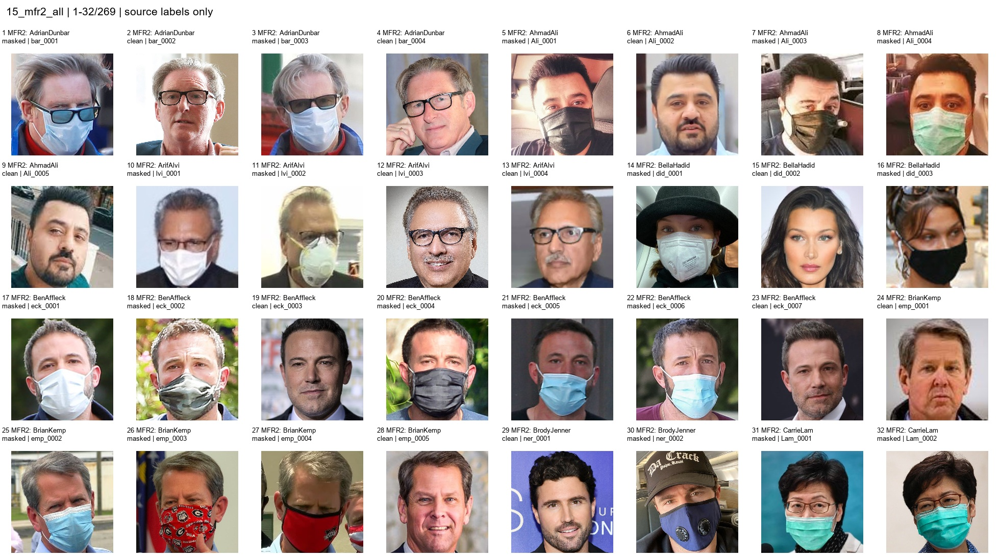

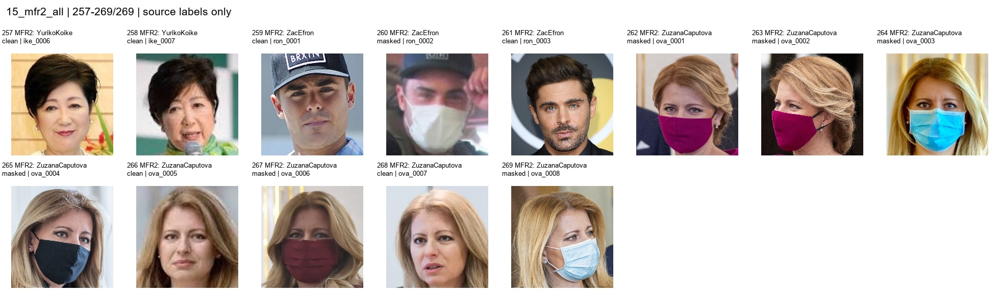

Đối chiếu tên file/nhãn: **269/269 khớp**. Đã xuất **9 trang / 269 ảnh** để kiểm điều kiện. Khớp schema không thay cho kiểm nội dung, và không thể xác định loại khẩu trang (KN95, N95…) chỉ từ ảnh.

In [18]:
mfr_base=ROOT/'data/raw/mfr2/mfr2';label_rows=[]
for line in (mfr_base/'mfr2_labels.txt').read_text(encoding='utf-8-sig').splitlines():
    if not line.strip():continue
    identity,index,kind=[t.strip() for t in line.split(',')]
    path=f'data/raw/mfr2/mfr2/{identity}/{identity}_{int(index):04d}.png'
    label_rows.append({'identity':identity,'index':int(index),'mask_type':kind,'path':path,
                      'condition':'clean' if kind=='no-mask' else 'masked'})
L=pd.DataFrame(label_rows);assert L.path.is_unique
mfr_check=M[M.source.eq('MFR2')].merge(L,on='path',suffixes=('_manifest','_source'),how='outer',indicator=True,validate='one_to_one')
assert mfr_check['_merge'].eq('both').all()
assert mfr_check.identity_manifest.eq(mfr_check.identity_source).all()
assert mfr_check.condition_manifest.eq(mfr_check.condition_source).all()
assert mfr_check.mask_type_manifest.eq(mfr_check.mask_type_source).all()
save(mfr_check,'13_mfr2_label_roundtrip')
pair_rows=[]
for line_no,line in enumerate((mfr_base/'pairs.txt').read_text(encoding='utf-8-sig').splitlines(),1):
    t=line.split()
    if not t:continue
    if len(t)==3:a,i,j=t;b=a
    elif len(t)==4:a,i,b,j=t
    else:raise ValueError((line_no,line))
    pa=f'{a}/{a}_{int(i):04d}.png';pb=f'{b}/{b}_{int(j):04d}.png'
    assert (mfr_base/pa).exists() and (mfr_base/pb).exists()
    pair_rows.append({'line':line_no,'a':pa,'b':pb,'same_person':a==b,'directed_key':pa+'|'+pb,
                      'undirected_key':'|'.join(sorted([pa,pb]))})
pair_protocol=pd.DataFrame(pair_rows);usage=pd.Series(pair_protocol.a.tolist()+pair_protocol.b.tolist()).value_counts()
pair_summary={'rows':len(pair_protocol),'positive':int(pair_protocol.same_person.sum()),
    'negative':int((~pair_protocol.same_person).sum()),'unique_undirected':pair_protocol.undirected_key.nunique(),
    'same_direction_repeats':int(pair_protocol.duplicated('directed_key').sum()),
    'additional_reversed':int(pair_protocol.duplicated('undirected_key').sum()-pair_protocol.duplicated('directed_key').sum()),
    'self_pair':int(pair_protocol.a.eq(pair_protocol.b).sum()),'images_used':len(usage),'images_reused':int(usage.gt(1).sum())}
save(pair_protocol,'13_mfr2_pairs');display(pd.DataFrame([pair_summary]))
mfr_pages,mfr_page_map=raw_sheets(M[M.source.eq('MFR2')].sort_values(['identity','path']),'15_mfr2_all',cols=8,per_page=32)
save(mfr_page_map,'13_mfr2_page_map');show_sheet(mfr_pages[0]);show_sheet(mfr_pages[-1])
display(Markdown(f'Đối chiếu tên file/nhãn: **{len(L)}/{len(L)} khớp**. Đã xuất **{len(mfr_pages)} trang / {len(L)} ảnh** để kiểm điều kiện. Khớp schema không thay cho kiểm nội dung, và không thể xác định loại khẩu trang (KN95, N95…) chỉ từ ảnh.'))

## 16. Bằng chứng review và kết luận từng cặp
Hai tệp đặt cạnh notebook là đầu vào có cấu trúc: `page_review_log.csv` ghi những trang đã thực sự xem (kèm SHA-256 của trang), `pair_review_decisions.csv` ghi nhận xét từng cặp. Trạng thái "đã xem" không được suy từ SSIM, pHash hay việc ảnh đã xuất ra sheet; mục nào chưa có log là `pending`.

Các kết luận cho cặp: `exact_pixel` (trùng pixel, kiểm bằng máy), `same_photo_visual` (xem ảnh thấy là cùng một ảnh/cảnh), `no_confirmed_duplicate` (chưa đủ bằng chứng trùng), `uncertain` (chưa chắc). Không kết luận nào cho phép suy hay đổi danh tính.

In [19]:
all_page_maps=pd.concat([flat_map,tiny_map,exact_map,pair_map,clip_map,multi_map,mfr_page_map],ignore_index=True)
all_pages=sorted(set(all_page_maps.sheet))
save(all_page_maps,'14_all_review_page_map')
review_path=QA/'page_review_log.csv';pair_review_path=QA/'pair_review_decisions.csv'
if not review_path.exists():
    pd.DataFrame({'sheet':all_pages,'review_status':'pending','reviewer':'','reviewed_at':'','scope_note':''}).to_csv(review_path,index=False,encoding='utf-8-sig')
if not pair_review_path.exists():
    P[['pair_id','image_id_a','image_id_b']].assign(finding='pending',reviewer='',evidence_sheet='',note='').to_csv(pair_review_path,index=False,encoding='utf-8-sig')
page_reviews=read_table(review_path);pair_reviews=read_table(pair_review_path)
assert page_reviews.sheet.is_unique and pair_reviews.pair_id.is_unique
assert set(page_reviews.sheet).issubset(set(all_pages)) and set(pair_reviews.pair_id)==set(P.pair_id)
allowed={'pending','exact_pixel','same_photo_visual','no_confirmed_duplicate','uncertain','degenerate_flat_candidate'}
assert set(pair_reviews.finding).issubset(allowed)
PR=P.merge(pair_reviews[['pair_id','finding','reviewer','evidence_sheet','note']],on='pair_id',validate='one_to_one')
reviewed_pages=set(page_reviews[page_reviews.review_status.eq('visually_reviewed')].sheet)
visual_pairs=PR[PR.finding.isin(['same_photo_visual','no_confirmed_duplicate','uncertain'])]
assert visual_pairs.evidence_sheet.isin(reviewed_pages).all(), 'Không đánh dấu cặp đã xem khi trang chưa có log'
save(PR,'14_pair_review_results')
display(page_reviews.groupby('review_status').size().rename('pages').to_frame());display(PR.finding.value_counts().to_frame('pairs'))
display(Markdown('Việc xem ảnh chỉ xác nhận những gì thấy được ở độ phân giải của sheet; chi tiết nhỏ hoặc danh tính chưa đủ bằng chứng vẫn để mở. **Các log này do trợ lý AI (Codex) ghi sau khi xem trang, chưa phải xác nhận của thành viên A/B/C.**'))
for r in page_reviews[page_reviews.review_status.eq('visually_reviewed')].itertuples():
    assert sha(SHEETS/r.sheet)==r.evidence_sha256, f'Trang review đã đổi: {r.sheet}; phải xem lại'
case_path=QA/'case_review_decisions.csv'
case_reviews=read_table(case_path)
assert case_reviews.case_id.is_unique
assert case_reviews.image_id.isin(M.image_id).all()
assert case_reviews.evidence_sheet.isin(reviewed_pages).all()
assert not case_reviews.identity_verified_independently.any()
save(case_reviews,'14_case_review_results')
review_hashes_start={p.name:sha(p) for p in [review_path,pair_review_path,case_path,asset_path,group_decisions_path]}
display(case_reviews.groupby(['finding','proposal']).size().rename('review_events').to_frame())
display(Markdown(f"Đã ghi **{len(case_reviews)} lượt review / {case_reviews.image_id.nunique()} ảnh** (một ảnh có thể xuất hiện ở nhiều trang). Review không xác minh danh tính; tên nguồn giữ nguyên. Trên 269 ảnh MFR2, ở độ phân giải sheet chưa thấy ảnh nào mâu thuẫn với nhãn có/không khẩu trang; không kết luận về việc khẩu trang có che kín mũi hay về loại khẩu trang. Ảnh cùng một người ở hai điều kiện còn khác nhau về góc, mũ, kính và ánh sáng."))


,pages
review_status,
visually_reviewed,62


,pairs
finding,
no_confirmed_duplicate,252
degenerate_flat_candidate,120
same_photo_visual,96
uncertain,15
exact_pixel,5


Việc xem ảnh chỉ xác nhận những gì thấy được ở độ phân giải của sheet; chi tiết nhỏ hoặc danh tính chưa đủ bằng chứng vẫn để mở. **Các log này do trợ lý AI (Codex) ghi sau khi xem trang, chưa phải xác nhận của thành viên A/B/C.**

,,review_events
finding,proposal,
clipping_reviewed_no_auto_reject,review,61
cross_label_registered_photo_candidate,hold,2
multibox_or_collage_subject_unverified,review,25
no_binary_mask_contradiction_at_sheet_scale,no_relabel,269
subject_box_mapping_uncertain,hold,1
unusable_or_misaligned_crop,hold,22


Đã ghi **380 lượt review / 379 ảnh** (một ảnh có thể xuất hiện ở nhiều trang). Review không xác minh danh tính; tên nguồn giữ nguyên. Trên 269 ảnh MFR2, ở độ phân giải sheet chưa thấy ảnh nào mâu thuẫn với nhãn có/không khẩu trang; không kết luận về việc khẩu trang có che kín mũi hay về loại khẩu trang. Ảnh cùng một người ở hai điều kiện còn khác nhau về góc, mũ, kính và ánh sáng.

### 16.1. Kiểm thêm bằng keypoint và căn chỉnh ảnh trong RAM
SSIM toàn khung có thể thấp khi cùng một ảnh bị crop lệch hoặc resize khác. Vì vậy với mọi cặp không có ảnh nền phẳng, ta tìm keypoint SIFT (Lowe ratio 0,75), ước lượng homography bằng RANSAC (ngưỡng 3 pixel) rồi so phần chồng lên nhau sau khi căn. Đây là phép so cấu trúc ảnh để tìm ảnh trùng, không phải nhận diện danh tính và không tạo dữ liệu cho model.

Ít điểm khớp hoặc căn thất bại không chứng minh hai ảnh khác nhau; nhiều điểm khớp cũng có thể đến từ tóc, nền hay phụ kiện. SSIM sau căn chỉnh chỉ hỗ trợ người xem; các cặp `uncertain` vẫn để mở, không tự nâng thành trùng bằng một ngưỡng.

pairs
source   status                           
DigiFace diagnostic_warp_available      24
         homography_failed               3
         insufficient_ratio_matches    214
         insufficient_texture            5
ROF      diagnostic_warp_available     119
         insufficient_ratio_matches      3

,n,median_inliers,median_registered_ssim,median_overlap
finding,,,,
exact_pixel,5,293.0,1.000000,1.000000
no_confirmed_duplicate,252,0.0,0.557011,0.786930
same_photo_visual,96,42.5,0.884207,0.945151
uncertain,15,68.0,0.866590,0.970050


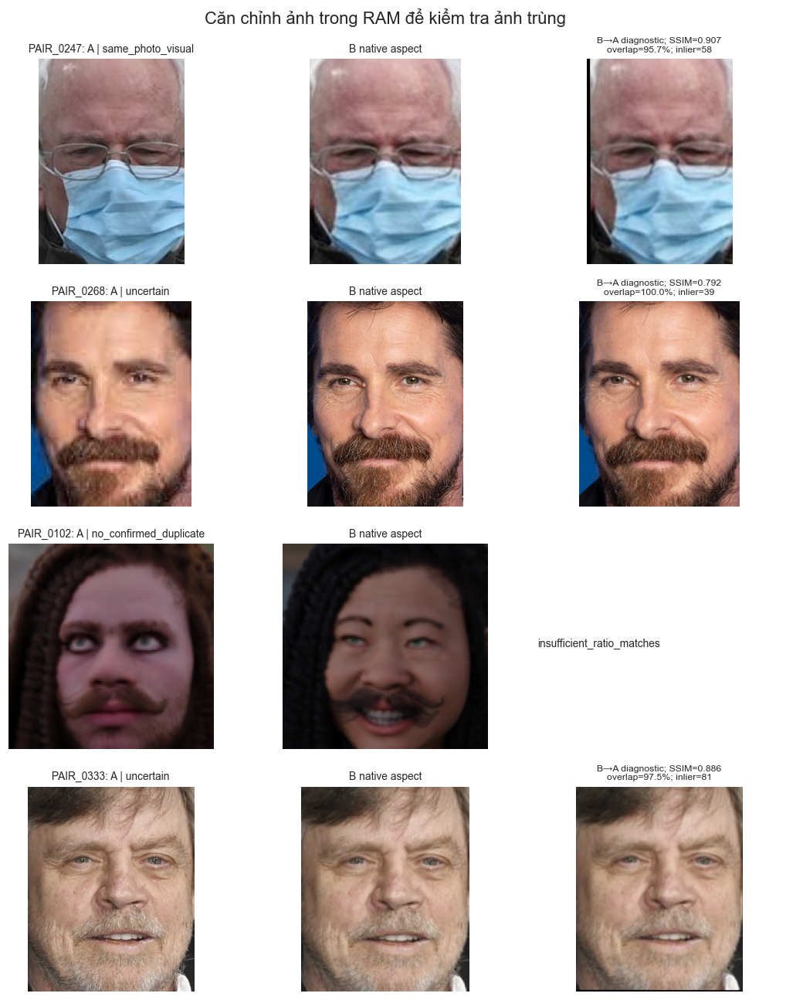

Các trung vị trên chỉ mô tả từng nhóm kết luận của người xem trên những cặp căn được, không phải độ chính xác của bộ phát hiện ảnh trùng. Homography trên khuôn mặt 3D có thể khớp một vùng nhưng lệch vùng khác. Ảnh đã căn không được dùng để train hay đánh giá.

,pair_id,identity_a,identity_b,finding,inliers,registered_ssim
0,PAIR_0281,elizabeth_olsen,emily_blunt,no_confirmed_duplicate,6,0.658568
1,PAIR_0303,jamie_lee_curtis,jeremy_renner,no_confirmed_duplicate,6,0.463158
2,PAIR_0310,jack_nicholson,josh_brolin,no_confirmed_duplicate,0,NaN
3,PAIR_0333,harrison_ford,mark_hamill,uncertain,81,0.886134
4,PAIR_0454,chris_evans,emilia_clarke,no_confirmed_duplicate,0,NaN
5,PAIR_0482,amber_heard,stefanos_tsitsipas,no_confirmed_duplicate,0,NaN


Bước sàng lọc cấu trúc làm thay đổi thứ tự ưu tiên review: PAIR_0333 có nhiều điểm khớp nhưng mang hai nhãn nguồn khác nhau, nên được ghi **uncertain + đề xuất tạm giữ**, không chọn nhãn đúng. PAIR_0272 và PAIR_0468 cũng được chuyển từ "chưa xác nhận trùng" sang `uncertain` sau khi xem thêm bằng chứng.

In [20]:
def registration_pair(r,return_images=False):
    aa=rgb_open(lookup.loc[r.image_id_a].path);bb=rgb_open(lookup.loc[r.image_id_b].path)
    def analysis_image(im):
        scale=min(2.0,512/max(im.size))
        return np.asarray(im.resize((max(1,round(im.width*scale)),max(1,round(im.height*scale))),Image.Resampling.BILINEAR))
    a,b=analysis_image(aa),analysis_image(bb)
    ga=cv2.cvtColor(a,cv2.COLOR_RGB2GRAY);gb=cv2.cvtColor(b,cv2.COLOR_RGB2GRAY)
    sift=cv2.SIFT_create(nfeatures=600)
    ka,da=sift.detectAndCompute(ga,None);kb,db=sift.detectAndCompute(gb,None)
    out={'pair_id':r.pair_id,'source':r.source_a,'status':'insufficient_texture','ratio_matches':0,
         'inliers':0,'inlier_fraction':np.nan,'overlap_fraction':np.nan,'registered_ssim':np.nan,
         'registered_mae_rgb':np.nan,'finding':r.finding}
    if da is None or db is None or len(db)<2:return (out,None) if return_images else out
    knn=cv2.BFMatcher(cv2.NORM_L2).knnMatch(da,db,k=2)
    good=[m for pair in knn if len(pair)==2 for m,nn in [pair] if m.distance<.75*nn.distance]
    out['ratio_matches']=len(good);out['status']='insufficient_ratio_matches'
    if len(good)<8:return (out,None) if return_images else out
    pa=np.float32([ka[m.queryIdx].pt for m in good]);pb=np.float32([kb[m.trainIdx].pt for m in good])
    cv2.setRNGSeed(SEED)
    hom,inliers=cv2.findHomography(pb,pa,cv2.RANSAC,3.0)
    if hom is None or not np.isfinite(hom).all():
        out['status']='homography_failed';return (out,None) if return_images else out
    out.update(inliers=int(inliers.sum()),inlier_fraction=float(inliers.mean()))
    warped=cv2.warpPerspective(b,hom,(a.shape[1],a.shape[0]))
    mask=cv2.warpPerspective(np.ones(b.shape[:2],np.uint8),hom,(a.shape[1],a.shape[0]),flags=cv2.INTER_NEAREST)
    mask=cv2.erode(mask,np.ones((11,11),np.uint8)).astype(bool)
    overlap=float(mask.mean());out['overlap_fraction']=overlap
    if mask.sum()<121:
        out['status']='insufficient_overlap';return (out,None) if return_images else out
    x=ga.astype(float);y=cv2.cvtColor(warped,cv2.COLOR_RGB2GRAY).astype(float)
    ux=cv2.GaussianBlur(x,(11,11),1.5);uy=cv2.GaussianBlur(y,(11,11),1.5)
    vx=cv2.GaussianBlur(x*x,(11,11),1.5)-ux*ux;vy=cv2.GaussianBlur(y*y,(11,11),1.5)-uy*uy
    cov=cv2.GaussianBlur(x*y,(11,11),1.5)-ux*uy
    sm=((2*ux*uy+6.5025)*(2*cov+58.5225))/((ux*ux+uy*uy+6.5025)*(vx+vy+58.5225))
    out.update(status='diagnostic_warp_available',registered_ssim=float(sm[mask].mean()),
               registered_mae_rgb=float(np.abs(a.astype(float)-warped.astype(float))[mask].mean()))
    return (out,(a,b,warped,mask)) if return_images else out
registration=pd.DataFrame([registration_pair(r) for r in PR[~PR.has_flat].itertuples()])
save(registration,'14_keypoint_registration')
display(registration.groupby(['source','status']).size().rename('pairs').to_frame())
display(registration.groupby('finding').agg(n=('pair_id','size'),median_inliers=('inliers','median'),
    median_registered_ssim=('registered_ssim','median'),median_overlap=('overlap_fraction','median')))
show_ids=['PAIR_0247','PAIR_0268','PAIR_0102','PAIR_0333']
fig,axes=plt.subplots(len(show_ids),3,figsize=(10,12))
for row_axes,pair_id in zip(axes,show_ids):
    r=next(r for r in PR.itertuples() if r.pair_id==pair_id)
    result,images=registration_pair(r,True)
    row_axes[0].imshow(rgb_open(lookup.loc[r.image_id_a].path));row_axes[0].set_title(f'{pair_id}: A | {r.finding}',fontsize=9)
    row_axes[1].imshow(rgb_open(lookup.loc[r.image_id_b].path));row_axes[1].set_title('B native aspect',fontsize=9)
    if images is not None:
        a,b,warped,mask=images;row_axes[2].imshow(warped)
        row_axes[2].set_title(f'B→A diagnostic; SSIM={result["registered_ssim"]:.3f}\noverlap={result["overlap_fraction"]:.1%}; inlier={result["inliers"]}',fontsize=8)
    else:row_axes[2].text(.05,.5,result['status'],transform=row_axes[2].transAxes,fontsize=9)
    for ax in row_axes:ax.axis('off')
fig.suptitle('Căn chỉnh ảnh trong RAM để kiểm tra ảnh trùng')
fig.tight_layout();finish(fig,'16_registration_diagnostics')
display(Markdown('Các trung vị trên chỉ mô tả từng nhóm kết luận của người xem trên những cặp căn được, không phải độ chính xác của bộ phát hiện ảnh trùng. Homography trên khuôn mặt 3D có thể khớp một vùng nhưng lệch vùng khác. Ảnh đã căn không được dùng để train hay đánh giá.'))
cross_registered=PR[(PR.source_a=='ROF') & ~PR.same_label & ~PR.pixel_equal].merge(
    registration[['pair_id','inliers','registered_ssim','overlap_fraction']],on='pair_id',validate='one_to_one')
save(cross_registered,'14_cross_label_registration_screen');display(cross_registered[['pair_id','identity_a','identity_b','finding','inliers','registered_ssim']])
display(Markdown('Bước sàng lọc cấu trúc làm thay đổi thứ tự ưu tiên review: PAIR_0333 có nhiều điểm khớp nhưng mang hai nhãn nguồn khác nhau, nên được ghi **uncertain + đề xuất tạm giữ**, không chọn nhãn đúng. PAIR_0272 và PAIR_0468 cũng được chuyển từ "chưa xác nhận trùng" sang `uncertain` sau khi xem thêm bằng chứng.'))


## 17. Hai loại nhóm: ảnh trùng và chung ảnh gốc
**photo_group** chỉ nối các ảnh trùng pixel và các cặp đã xem là cùng một ảnh. **leakage_group** nối thêm các crop có chung URL/ảnh gốc, để một cảnh không bị chia sang cả gallery lẫn query hay sang các tập khác nhau. Hai crop chung một cảnh có thể là hai người khác nhau, nên không dùng leakage_group để gộp danh tính hay chọn ảnh đại diện.

Cặp pHash còn chờ, cặp báo nhầm và ảnh nền phẳng không tạo cạnh trùng ảnh. Ứng viên trùng tên giữa các nguồn vẫn chờ xác minh, chưa nhập vào danh tính chính thức. Đây chỉ là ràng buộc cho bước thiết kế protocol, chưa chia train/val/test.

In [21]:
class DSU:
    def __init__(self,items):self.parent={x:x for x in items}
    def find(self,x):
        while self.parent[x]!=x:
            self.parent[x]=self.parent[self.parent[x]];x=self.parent[x]
        return x
    def union(self,a,b):
        ra,rb=self.find(a),self.find(b)
        if ra!=rb:self.parent[max(ra,rb)]=min(ra,rb)
    def groups(self):
        result=defaultdict(list)
        for x in self.parent:result[self.find(x)].append(x)
        return list(result.values())
photo=DSU(M.image_id);leak=DSU(M.image_id);edge_rows=[]
def add_edge(a,b,kind,photo_edge=False):
    leak.union(a,b)
    if photo_edge:photo.union(a,b)
    edge_rows.append({'image_id_a':a,'image_id_b':b,'evidence':kind,'photo_edge':photo_edge,
                      'is_identity_merge':False,'split_assignment':'unassigned'})
for _,g in exact.groupby('group_id'):
    ids=sorted(g.image_id)
    for b in ids[1:]:add_edge(ids[0],b,'exact_pixel',True)
for r in PR[PR.finding.eq('same_photo_visual') & ~PR.has_flat & ~PR.pixel_equal].itertuples():
    add_edge(r.image_id_a,r.image_id_b,'same_photo_visual_review',True)
for _,g in M[M.source.eq('ROF')].groupby('original_id'):
    ids=sorted(g.image_id)
    for b in ids[1:]:add_edge(ids[0],b,'same_source_scene',False)
for _,g in B_all[B_all.image_id.isin(set(M.image_id))].groupby('source_sha256_now'):
    ids=sorted(g.image_id)
    for b in ids[1:]:add_edge(ids[0],b,'same_encoded_source_bytes',False)
edges=save(pd.DataFrame(edge_rows),'15_leakage_edges')
def group_map(dsu,prefix):
    result={}
    for group in dsu.groups():
        key=prefix+hashlib.sha256('|'.join(sorted(group)).encode()).hexdigest()[:16]
        for image_id in group:result[image_id]=key
    return result
photo_map=group_map(photo,'PHOTO_');leak_map=group_map(leak,'SCENE_')
groups_manifest=M[['image_id','source','identity','condition','original_id','split']].copy()
groups_manifest['photo_group']=groups_manifest.image_id.map(photo_map)
groups_manifest['leakage_group']=groups_manifest.image_id.map(leak_map)
save(groups_manifest,'15_group_constraints')
display(edges.evidence.value_counts().to_frame('edges'))
display(pd.DataFrame([{'type':'photo','groups_size_gt1':sum(len(g)>1 for g in photo.groups()),'images_in_groups':sum(len(g) for g in photo.groups() if len(g)>1)},
                      {'type':'leakage/scene','groups_size_gt1':sum(len(g)>1 for g in leak.groups()),'images_in_groups':sum(len(g) for g in leak.groups() if len(g)>1)}]))
display(Markdown('Mỗi cạnh là bằng chứng cùng pixel, cùng ảnh hoặc cùng cảnh, không phải bằng chứng hai nhãn là cùng người. Mâu thuẫn nhãn phải được giải quyết trước khi chia tập; ràng buộc cùng URL/cùng cảnh cũng phải giữ khi tách gallery/query.'))
photo_inventory=groups_manifest.groupby('photo_group').agg(
    images=('image_id','size'),labels=('identity','nunique'),conditions=('condition','nunique'))
photo_inventory=photo_inventory[photo_inventory.images.gt(1)].reset_index()
save(photo_inventory,'15_photo_group_summary')
photo_condition_groups=set(photo_inventory[photo_inventory.conditions.gt(1)].photo_group)
save(groups_manifest[groups_manifest.photo_group.isin(photo_condition_groups)],'15_photo_condition_conflicts')
display(Markdown(f"Trong các nhóm trùng pixel có **{exact[exact.conditions_in_group.gt(1)].group_id.nunique()} nhóm khác điều kiện**. Khi thêm các cặp đã xem là cùng ảnh, có **{len(photo_condition_groups)} nhóm ảnh mang nhiều điều kiện**. Nhóm cần chốt cách định nghĩa điều kiện (clean/sunglasses), chưa tự gán lại nhãn. Các nhóm ảnh từ review được lập theo hướng thận trọng để chống rò rỉ, chưa phải căn cứ để xóa ảnh trùng."))


,edges
evidence,
same_encoded_source_bytes,451
same_source_scene,420
same_photo_visual_review,96
exact_pixel,5


,type,groups_size_gt1,images_in_groups
0,photo,95,193
1,leakage/scene,392,936


Mỗi cạnh là bằng chứng cùng pixel, cùng ảnh hoặc cùng cảnh, không phải bằng chứng hai nhãn là cùng người. Mâu thuẫn nhãn phải được giải quyết trước khi chia tập; ràng buộc cùng URL/cùng cảnh cũng phải giữ khi tách gallery/query.

Trong các nhóm trùng pixel có **3 nhóm khác điều kiện**. Khi thêm các cặp đã xem là cùng ảnh, có **7 nhóm ảnh mang nhiều điều kiện**. Nhóm cần chốt cách định nghĩa điều kiện (clean/sunglasses), chưa tự gán lại nhãn. Các nhóm ảnh từ review được lập theo hướng thận trọng để chống rò rỉ, chưa phải căn cứ để xóa ảnh trùng.

## 18. Manifest QA đề xuất: bằng chứng, mức độ và hành động
Quy tắc được đặt trước khi có bất kỳ kết quả nhận diện nào và không tối ưu theo test. Ba trạng thái:

- **Tạm giữ (hold):** chưa đưa **bản crop hiện tại** vào pipeline để điều tra thêm; không xóa raw.
- **Cần xem (review):** cần xem thêm, chưa coi là lỗi.
- **Ứng viên (candidate):** chưa phát hiện lỗi ở các phép kiểm đã chạy; không có nghĩa dữ liệu đã sạch.

Thứ tự ưu tiên: mâu thuẫn nhãn, crop không có thông tin hoặc quá nhỏ → nhiều box chưa rõ người → bản trùng phụ → xem lại box/detector/chất lượng → ứng viên. Mỗi ảnh chỉ có một dòng dù có nhiều lý do. Cờ 1% đuôi chất lượng chỉ để chẩn đoán, không loại theo phân vị.
Quyết định của nhóm được lưu riêng trong `qa/group_decisions.csv` và chỉ đọc khi chạy lại. `qa_action_proposed` là đề xuất tự sinh; `group_decision` là quyết định ghi nhận, chưa tự áp dụng. Dòng chưa có quyết định vẫn ở trạng thái chờ, không được coi là đã duyệt.


In [22]:
GROUP_DECISION_COLUMNS=['image_id','reviewer_ABC','group_decision','decision_reason','reviewed_at','evidence_reference']

def merge_group_decisions(base_manifest, decisions):
    """Đọc quyết định đã ghi; không áp dụng đề xuất, sửa nhãn hoặc ghi lại input."""
    if list(decisions.columns)!=GROUP_DECISION_COLUMNS:
        raise ValueError('group_decisions.csv sai schema; cần đúng sáu cột đã hướng dẫn')
    if not base_manifest.image_id.is_unique:
        raise ValueError('Manifest phải có image_id duy nhất')
    reviewed=decisions.copy().fillna('').astype(str)
    for column in GROUP_DECISION_COLUMNS:
        reviewed[column]=reviewed[column].str.strip()
    if reviewed.image_id.duplicated().any():
        raise ValueError('group_decisions.csv có image_id lặp; cần một quyết định hiện hành mỗi ảnh')
    if not reviewed.image_id.isin(base_manifest.image_id).all():
        raise ValueError('group_decisions.csv chứa image_id không thuộc manifest hiện tại')
    if reviewed.eq('').any(axis=None):
        raise ValueError('Mỗi dòng quyết định cần đủ image_id, người duyệt, quyết định, lý do, ngày và bằng chứng')
    allowed={'approve_proposal','keep','hold','exclude'}
    if not reviewed.group_decision.isin(allowed).all():
        raise ValueError('group_decision chỉ nhận approve_proposal, keep, hold hoặc exclude; ô rỗng không phải xác nhận')
    for value in reviewed.reviewed_at:
        try:
            datetime.fromisoformat(value.replace('Z','+00:00'))
        except ValueError as error:
            raise ValueError('reviewed_at cần ngày ISO 8601, ví dụ YYYY-MM-DD') from error
    annotation_columns=GROUP_DECISION_COLUMNS[1:]+['decision_status','group_review_recorded']
    result=base_manifest.drop(columns=annotation_columns,errors='ignore').merge(
        reviewed,on='image_id',how='left',sort=False,validate='one_to_one')
    result[GROUP_DECISION_COLUMNS[1:]]=result[GROUP_DECISION_COLUMNS[1:]].fillna('')
    result['group_review_recorded']=result.group_decision.ne('')
    result['decision_status']=np.where(result.group_review_recorded,'group_decision_recorded','awaiting_group_review')
    return result

flags=defaultdict(set)
def flag(ids,reason):
    for x in ids:flags[x].add(reason)
flag(case_reviews[case_reviews.proposal.eq('hold')].image_id,'hold_manual_crop_or_subject_review')
flag(placeholder_ids,'hold_verified_logo_source_asset')
flag(flat.image_id,'hold_low_information_crop')
flag(tiny.image_id,'hold_below_baseline_min_side20')
flag(conflict_ids,'hold_exact_pixel_cross_label')
flag(multi.image_id,'hold_subject_box_mapping_unresolved')
flag(clip.image_id,'review_author_box_clipped')
flag(geometry[geometry.landmarks_outside_crop.gt(0)|geometry.landmarks_outside_canvas.gt(0)].image_id,'review_source_landmark_geometry')
flag(M[(M.aspect_ratio<.35)|(M.aspect_ratio>2)].image_id,'review_extreme_aspect_ratio')
flag(crop_det[~crop_det.status.eq('single_face')].image_id,'review_detector_policy_failure')
pending_pairs=PR[PR.finding.isin(['pending','uncertain']) & ~PR.has_flat & ~PR.pixel_equal]
flag(set(pending_pairs.image_id_a)|set(pending_pairs.image_id_b),'review_near_pair_unresolved')
for r in old_queue.itertuples():
    for reason in str(r.reasons).split('|'):
        if reason.startswith('P2_'):flags[r.image_id].add('review_quality_tail_proxy')

# Chọn đại diện đề xuất trong nhóm ảnh trùng, không dùng nhóm chung cảnh.
secondary=set();cross_photo=set();cross_condition=set()
for group in photo.groups():
    if len(group)<2:continue
    g=lookup.loc[group]
    if g.canonical_identity.nunique()>1:
        cross_photo.update(group);continue
    if g.condition.nunique()>1:
        cross_condition.update(group);continue
    secondary.update(sorted(group)[1:])
flag(cross_photo,'hold_confirmed_photo_cross_label')
flag(cross_condition,'hold_photo_condition_conflict')
flag(secondary,'proposed_duplicate_secondary')
manifest=M[['image_id','source','identity','condition','mask_type','path','canonical_identity','split','sha256','pixel_sha256']].copy()
manifest['photo_group']=manifest.image_id.map(photo_map);manifest['leakage_group']=manifest.image_id.map(leak_map)
manifest['qa_reasons']=manifest.image_id.map(lambda x:'|'.join(sorted(flags[x])))
manifest['detector_audited']=manifest.image_id.isin(set(crop_det.image_id))
manifest['identity_verified_independently']=False
def action(reasons):
    r=set(reasons.split('|'))
    if any(x.startswith('hold_') for x in r):return 'hold_proposed'
    if 'proposed_duplicate_secondary' in r:return 'duplicate_secondary_proposed'
    if any(x.startswith('review_') for x in r):return 'review_required'
    return 'candidate_no_detected_blocker'
manifest['qa_action_proposed']=manifest.qa_reasons.map(action)
# Input do nhóm quản lý; notebook chỉ đọc, không tự tạo xác nhận.
group_decisions=pd.read_csv(group_decisions_path,dtype=str,keep_default_na=False)
manifest=merge_group_decisions(manifest,group_decisions)
save(manifest,'16_QA_manifest_proposed')
queue=manifest[~manifest.qa_action_proposed.eq('candidate_no_detected_blocker')].copy()
save(queue,'16_QA_action_queue')
action_summary=manifest.groupby(['source','condition','qa_action_proposed']).size().rename('images').reset_index()
save(action_summary,'16_action_summary');display(action_summary)
flag_summary=save(pd.DataFrame([{'reason':f,'images':sum(f in flags[x] for x in M.image_id)}
                               for f in sorted(set().union(*flags.values()))]),'16_reason_counts')
display(flag_summary)
display(Markdown(f'Đề xuất **{vn(manifest.qa_action_proposed.eq("hold_proposed").sum())} ảnh tạm giữ**, **{vn(manifest.qa_action_proposed.eq("duplicate_secondary_proposed").sum())} bản trùng phụ** và **{vn(manifest.qa_action_proposed.eq("review_required").sum())} ảnh cần xem**. Đây mới là đề xuất: chưa xóa, chuyển file hay sửa nhãn. Một ảnh có thể có nhiều lý do nên không cộng cột `images` của bảng lý do thành số ảnh lỗi.'))
display(Markdown(f'**Quyết định của nhóm đã ghi: {vn(manifest.group_review_recorded.sum())} ảnh.** Bảng giữ riêng `qa_action_proposed` và `group_decision`; đọc quyết định không tự áp dụng hold/exclude, không xác minh danh tính và không tạo split.'))


,source,condition,qa_action_proposed,images
0,DigiFace,synthetic_unannotated,candidate_no_detected_blocker,77552
1,DigiFace,synthetic_unannotated,review_required,2448
2,MFR2,clean,candidate_no_detected_blocker,93
3,MFR2,clean,review_required,5
4,MFR2,masked,candidate_no_detected_blocker,154
5,MFR2,masked,review_required,17
6,ROF,clean,candidate_no_detected_blocker,3652
7,ROF,clean,duplicate_secondary_proposed,44
8,ROF,clean,hold_proposed,409
9,ROF,clean,review_required,251


,reason,images
0,hold_below_baseline_min_side20,14
1,hold_confirmed_photo_cross_label,2
2,hold_exact_pixel_cross_label,2
3,hold_low_information_crop,18
4,hold_manual_crop_or_subject_review,25
5,hold_photo_condition_conflict,15
6,hold_subject_box_mapping_unresolved,723
7,hold_verified_logo_source_asset,34
8,proposed_duplicate_secondary,89
9,review_author_box_clipped,83


Đề xuất **804 ảnh tạm giữ**, **82 bản trùng phụ** và **2.946 ảnh cần xem**. Đây mới là đề xuất: chưa xóa, chuyển file hay sửa nhãn. Một ảnh có thể có nhiều lý do nên không cộng cột `images` của bảng lý do thành số ảnh lỗi.

**Quyết định của nhóm đã ghi: 0 ảnh.** Bảng giữ riêng `qa_action_proposed` và `group_decision`; đọc quyết định không tự áp dụng hold/exclude, không xác minh danh tính và không tạo split.

## 19. Tác động nếu áp dụng đề xuất
So hai kịch bản. **A** chỉ tạm giữ lỗi cấu trúc rõ ràng (crop ít thông tin, nhỏ hơn mức tối thiểu của MTCNN, mâu thuẫn nhãn, các ca đã xem ảnh). **B** giữ thêm nhóm nhiều box chưa rõ người và bản trùng phụ. Ảnh "cần xem" vẫn được tính là còn lại trong mô phỏng này, nhưng chưa được duyệt để dùng chính thức.

Tác động được đo theo từng nguồn/điều kiện và theo số danh tính còn đủ ảnh rõ cho gallery và ảnh khẩu trang cho query. Không lấy ảnh ROF/MFR2 đưa vào train để bù thiếu; chưa khóa split.

,scenario,source,condition,original_images,remaining_images,remaining_fraction,original_labels,remaining_labels
0,before_QA,DigiFace,synthetic_unannotated,80000,80000,1.000000,2000,2000
1,before_QA,MFR2,clean,98,98,1.000000,53,53
2,before_QA,MFR2,masked,171,171,1.000000,53,53
3,before_QA,ROF,clean,4356,4356,1.000000,181,181
4,before_QA,ROF,masked,264,264,1.000000,57,57
5,before_QA,ROF,sunglasses,2091,2091,1.000000,157,157
6,A_structure_only,DigiFace,synthetic_unannotated,80000,80000,1.000000,2000,2000
7,A_structure_only,MFR2,clean,98,98,1.000000,53,53
8,A_structure_only,MFR2,masked,171,171,1.000000,53,53
9,A_structure_only,ROF,clean,4356,4287,0.984160,181,181


,scenario,source,labels_remaining,IDs_clean_and_masked,IDs_2clean_and_masked,IDs_no_clean
0,before_QA,ROF,182,57,57,1
1,before_QA,MFR2,53,53,45,0
2,A_structure_only,ROF,182,57,57,1
3,A_structure_only,MFR2,53,53,45,0
4,B_plus_ambiguity_duplicates,ROF,182,55,55,1
5,B_plus_ambiguity_duplicates,MFR2,53,53,45,0


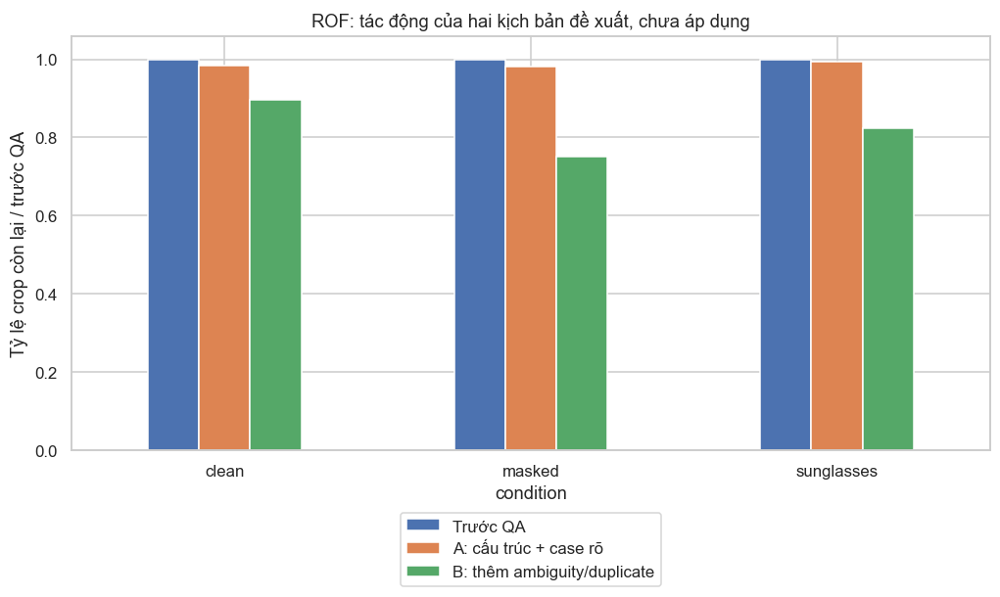

Nếu điều kiện khẩu trang mất ảnh/người nhiều hơn ảnh rõ, phải báo rõ thiên lệch do QA gây ra và số người còn đủ gallery/query. Không trình bày kết quả trên tập đã lọc như là model tốt hơn; lưu dữ liệu trước/sau và báo cả độ phủ.

**Tác động đáng chú ý:** với kịch bản B, ROF khẩu trang còn 198/264 crop (75,0%) và 55 nhãn có cả ảnh rõ lẫn ảnh khẩu trang. Cần cân nhắc thiên lệch và độ phủ trước khi áp dụng chính sách tạm giữ.

In [23]:
hard_reasons={'hold_verified_logo_source_asset','hold_manual_crop_or_subject_review','hold_low_information_crop','hold_below_baseline_min_side20','hold_exact_pixel_cross_label',
              'hold_confirmed_photo_cross_label','hold_photo_condition_conflict'}
drop_A={x for x in M.image_id if flags[x]&hard_reasons}
drop_B=set(manifest[manifest.qa_action_proposed.isin(['hold_proposed','duplicate_secondary_proposed'])].image_id)
scenarios={'before_QA':set(),'A_structure_only':drop_A,'B_plus_ambiguity_duplicates':drop_B}
impact_rows=[];gallery_rows=[]
for scenario,excluded in scenarios.items():
    selected=M[~M.image_id.isin(excluded)]
    for (source,condition),g in M.groupby(['source','condition']):
        remain=selected[(selected.source==source)&(selected.condition==condition)]
        impact_rows.append({'scenario':scenario,'source':source,'condition':condition,'original_images':len(g),
            'remaining_images':len(remain),'remaining_fraction':len(remain)/len(g),
            'original_labels':g.identity.nunique(),'remaining_labels':remain.identity.nunique()})
    for source in ['ROF','MFR2']:
        per_id=selected[selected.source.eq(source)].groupby(['identity','condition']).size().unstack(fill_value=0)
        clean=per_id.get('clean',pd.Series(0,index=per_id.index));masked=per_id.get('masked',pd.Series(0,index=per_id.index))
        gallery_rows.append({'scenario':scenario,'source':source,'labels_remaining':len(per_id),
            'IDs_clean_and_masked':int((clean.ge(1)&masked.ge(1)).sum()),
            'IDs_2clean_and_masked':int((clean.ge(2)&masked.ge(1)).sum()),
            'IDs_no_clean':int(clean.eq(0).sum())})
impact=save(pd.DataFrame(impact_rows),'17_scenario_impact');gallery=save(pd.DataFrame(gallery_rows),'17_gallery_feasibility')
display(impact);display(gallery)
fig,ax=plt.subplots(figsize=(11,5))
plot=impact[impact.source.eq('ROF')].pivot(index='condition',columns='scenario',values='remaining_fraction')
plot=plot.reindex(columns=['before_QA','A_structure_only','B_plus_ambiguity_duplicates'])
plot.columns=['Trước QA','A: cấu trúc + case rõ','B: thêm ambiguity/duplicate']
plot.plot.bar(ax=ax);ax.set(ylabel='Tỷ lệ crop còn lại / trước QA',title='ROF: tác động của hai kịch bản đề xuất, chưa áp dụng',ylim=(0,1.06));ax.tick_params(axis='x',rotation=0);ax.legend(loc='upper center',bbox_to_anchor=(.5,-.13),ncol=1)
finish(fig,'19_qa_impact')
display(Markdown('Nếu điều kiện khẩu trang mất ảnh/người nhiều hơn ảnh rõ, phải báo rõ thiên lệch do QA gây ra và số người còn đủ gallery/query. Không trình bày kết quả trên tập đã lọc như là model tốt hơn; lưu dữ liệu trước/sau và báo cả độ phủ.'))
bmask=impact[(impact.scenario=='B_plus_ambiguity_duplicates')&(impact.source=='ROF')&(impact.condition=='masked')].iloc[0]
bgal=gallery[(gallery.scenario=='B_plus_ambiguity_duplicates')&(gallery.source=='ROF')].iloc[0]
display(Markdown(f"**Tác động đáng chú ý:** với kịch bản B, ROF khẩu trang còn {bmask.remaining_images}/{bmask.original_images} crop ({pct(bmask.remaining_fraction,1)}) và {bgal.IDs_clean_and_masked} nhãn có cả ảnh rõ lẫn ảnh khẩu trang. Cần cân nhắc thiên lệch và độ phủ trước khi áp dụng chính sách tạm giữ."))


## 20. Các quyết định nhóm cần chốt trước preprocessing
Kiểm tra cơ học đã xong nhưng phần kiểm nội dung (đúng người, đúng điều kiện) vẫn còn. Bảng dưới liệt kê từng quyết định, bằng chứng, đề xuất và người phụ trách A/B/C (nhóm tự điền tên); các mục chưa có nguồn xác minh được cố ý để mở.

In [24]:
decision_board=pd.DataFrame([
 {'item':'Exact pixel khác nhãn','evidence':'07_exact_members.csv + cùng pixel + context nguồn','proposal':'Tạm giữ cả hai crop; không tự chọn nhãn đúng','owner':'A/C','status':'needs_group_confirmation'},
 {'item':'Crop gần một màu/quá nhỏ','evidence':'06_* + contact sheets','proposal':'Tạm giữ bản crop hiện tại; xem có thể sửa annotation ở bước riêng','owner':'A','status':'needs_group_confirmation'},
 {'item':'Entry nhiều box dưới một nhãn','evidence':'10_multiple_author_boxes_acquired.csv + context','proposal':'Tạm giữ cho tới khi có subject-box mapping; không chọn face_index=0','owner':'A/C','status':'needs_semantic_ground_truth'},
 {'item':'Clipping và landmark ngoài khung','evidence':'09_* + 11_*','proposal':'Xem ảnh gốc/crop trước khi đề xuất sửa box; không loại mọi ảnh có bbox detector vượt khung','owner':'A/B','status':'review_geometry'},
 {'item':'Gần trùng đã review/còn pending','evidence':'14_pair_review_results.csv','proposal':'Nhóm photo để tránh leakage; cặp chưa xác nhận không merge ID','owner':'A/C','status':'review_log_available'},
 {'item':'Alias giữa ROF/MFR2','evidence':'12_alias_mapping_candidates.csv','proposal':'Xác nhận bằng mapping nguồn độc lập hoặc xử lý bảo thủ trong protocol','owner':'A/C','status':'mapping_pending'},
 {'item':'Protocol MFR2','evidence':'13_mfr2_pairs.csv','proposal':'Giữ file official; báo unique-pair sensitivity riêng nếu dùng','owner':'C','status':'protocol_decision_pending'},
 {'item':'Preprocessing pilot','evidence':'QA manifest + crop/scene association','proposal':'Chỉ bắt đầu sau khi nhóm duyệt kết quả QA; so resize thẳng và chạy lại detector với cùng quy ước đầu vào','owner':'A/B/C','status':'not_started'}])
decision_board=pd.concat([decision_board,pd.DataFrame([{'item':'Cùng ảnh, khác condition clean/sunglasses','evidence':'07_exact_members + photo group summary','proposal':'Chốt định nghĩa condition; tạm giữ nhóm mâu thuẫn, không tự relabel','owner':'A/C','status':'condition_mapping_pending'}])],ignore_index=True)
save(decision_board,'18_group_decision_board');display(decision_board)

,item,evidence,proposal,owner,status
0,Exact pixel khác nhãn,07_exact_members.csv + cùng pixel + context nguồn,Tạm giữ cả hai crop; không tự chọn nhãn đúng,A/C,needs_group_confirmation
1,Crop gần một màu/quá nhỏ,06_* + contact sheets,Tạm giữ bản crop hiện tại; xem có thể sửa annotation ở bước riêng,A,needs_group_confirmation
2,Entry nhiều box dưới một nhãn,10_multiple_author_boxes_acquired.csv + context,Tạm giữ cho tới khi có subject-box mapping; không chọn face_index=0,A/C,needs_semantic_ground_truth
3,Clipping và landmark ngoài khung,09_* + 11_*,Xem ảnh gốc/crop trước khi đề xuất sửa box; không loại mọi ảnh có bbox ...,A/B,review_geometry
4,Gần trùng đã review/còn pending,14_pair_review_results.csv,Nhóm photo để tránh leakage; cặp chưa xác nhận không merge ID,A/C,review_log_available
5,Alias giữa ROF/MFR2,12_alias_mapping_candidates.csv,Xác nhận bằng mapping nguồn độc lập hoặc xử lý bảo thủ trong protocol,A/C,mapping_pending
6,Protocol MFR2,13_mfr2_pairs.csv,Giữ file official; báo unique-pair sensitivity riêng nếu dùng,C,protocol_decision_pending
7,Preprocessing pilot,QA manifest + crop/scene association,Chỉ bắt đầu sau khi nhóm duyệt kết quả QA; so resize thẳng và chạy lại ...,A/B/C,not_started
8,"Cùng ảnh, khác condition clean/sunglasses",07_exact_members + photo group summary,"Chốt định nghĩa condition; tạm giữ nhóm mâu thuẫn, không tự relabel",A/C,condition_mapping_pending


## 21. Kiểm tra nhất quán
Kiểm số dòng, hash, việc dựng lại crop, các cạnh của đồ thị nhóm, mẫu số của các kịch bản và việc đầu vào không đổi trong lúc chạy. Log review không được trỏ tới trang chưa xem.

In [25]:
assert len(manifest)==len(M) and manifest.image_id.is_unique
assert manifest['split'].eq('unassigned').all()
assert not manifest.identity_verified_independently.any()
assert set(manifest.identity)==set(M.identity)
assert raw_check.matches_eda.all() and B.crop_pixel_matches_annotation.all()
assert exact.image_id.isin(M.image_id).all()
assert PR.pair_id.is_unique and len(PR)==len(N)
assert len(PR[~PR.has_flat])==len(pair_map)
assert edges.image_id_a.isin(M.image_id).all() and edges.image_id_b.isin(M.image_id).all()
for r in edges.itertuples():
    assert leak_map[r.image_id_a]==leak_map[r.image_id_b]
    if r.photo_edge:assert photo_map[r.image_id_a]==photo_map[r.image_id_b]
for _,g in impact.groupby(['source','condition']):
    n=g[g.scenario.eq('before_QA')].remaining_images.iloc[0]
    assert g.remaining_images.le(n).all()
for r in inputs.itertuples():assert sha(ROOT/r.path)==r.sha256,'Input thay đổi trong lúc QA'
assert int(manifest.group_review_recorded.sum())==len(group_decisions)
assert manifest.qa_action_proposed.value_counts().sum()==len(M)
save(pd.DataFrame(scan_provenance),'19_scan_provenance')
review_hashes={p.name:sha(p) for p in [review_path,pair_review_path,case_path,asset_path,group_decisions_path]}
assert review_hashes==review_hashes_start, 'Review inputs thay đổi trong lúc chạy'
summary={'raw_images':len(M),'raw_bytes_match':int(raw_check.matches_eda.sum()),
    'annotation_rows':len(A),'annotation_labels':A.identity.nunique(),
    'acquired_rof_crops':len(B),'acquired_rof_labels':M[M.source.eq('ROF')].identity.nunique(),
    'source_images_reconstructed':len(groups),'crop_pixel_matches':int(B.crop_pixel_matches_annotation.sum()),
    'exact_groups':exact.group_id.nunique(),'exact_cross_label_images':len(conflict_ids),
    'near_pairs':len(PR),'pair_review_findings':PR.finding.value_counts().to_dict(),
    'verified_logo_assets':len(assets),'logo_descendant_crops':len(placeholder_ids),'flat_crops':len(flat),'tiny_crops':len(tiny),'clipped_source_boxes':len(clip),'downloaded_annotation_rows':len(B_all),'downloaded_but_invalid_box':len(failed_box_rows),
    'exact_condition_conflict_groups':int(exact[exact.conditions_in_group.gt(1)].group_id.nunique()),
    'manual_hold_unique_images':int(case_reviews[case_reviews.proposal.eq('hold')].image_id.nunique()),
    'multi_box_acquired':len(multi),'alias_candidates':len(aliases),
    'review_pages_total':len(all_pages),'review_pages_viewed':len(reviewed_pages),
    'proposed_actions':manifest.qa_action_proposed.value_counts().to_dict(),
    'group_decision_rows':len(group_decisions),'group_reviewed_images':int(manifest.group_review_recorded.sum()),
    'group_decisions_applied':False,'scan_modes':{row['name']:row['mode'] for row in scan_provenance},
    'review_input_sha256':review_hashes,'checks':'PASS','preprocessing_started':False,
    'raw_deleted_or_modified':False,'labels_reassigned':False,'split_assigned':False,'trained':False}
(OUT/'qa_execution_summary.json').write_text(json.dumps(summary,ensure_ascii=False,indent=2),encoding='utf-8')
display(pd.DataFrame([{'check':'Snapshot integrity + parser + crop pixel replay','result':'PASS'},
                      {'check':'Graph/manifest/sample denominator consistency','result':'PASS'},
                      {'check':'Input hashes unchanged at end','result':'PASS'},
                      {'check':'Preprocessing/split/training','result':'NOT STARTED'}]))

,check,result
0,Snapshot integrity + parser + crop pixel replay,PASS
1,Graph/manifest/sample denominator consistency,PASS
2,Input hashes unchanged at end,PASS
3,Preprocessing/split/training,NOT STARTED


## 22. Kết quả QA để nhóm duyệt trước khi sang preprocessing

In [26]:
display(Markdown(f"""
### Đã kiểm chứng
- **{vn(len(raw_check))} ảnh** khớp bytes với EDA; đọc lại đủ **{vn(len(A))} box** từ pickle nguồn.
- **{vn(len(B))} crop ROF / {vn(len(groups))} ảnh gốc** khớp pixel với công thức crop (kiểm cách cắt, không chứng nhận đúng người).
- **{exact.group_id.nunique()} nhóm trùng pixel**, **{len(conflict_ids)} ảnh mâu thuẫn nhãn**; **{len(flat)} crop gần như một màu**, **{len(tiny)} crop quá nhỏ với MTCNN**, **{len(clip)} crop bị cắt biên**.
- Các entry nhiều box có **{vn(len(multi))} crop đã tải**, cần xác định box nào thuộc người được gán nhãn trước khi dùng để đánh giá.
- Toàn bộ **{len(PR)} cặp pHash** đã có chỉ số và trạng thái review; **{len(reviewed_pages)}/{len(all_pages)} trang** contact sheet đã được xem. Chi tiết từng cặp ở phần 16.

**Cần chú ý:** {exact[exact.conditions_in_group.gt(1)].group_id.nunique()} nhóm trùng pixel mang hai điều kiện khác nhau; các nhóm ảnh nhiều điều kiện sau review nằm trong `15_photo_condition_conflicts.csv`. Các crop mất mặt hoặc chỉ có nền được ghi riêng trong case review.

**Truy nguồn gốc:** {len(assets)} file logo bị nhiều URL trả về, ảnh hưởng {len(placeholder_ids)} crop; đã đưa vào đề xuất tạm giữ.

### Giới hạn và quyết định còn mở
Chưa xác minh danh tính người thật bằng nguồn tham chiếu độc lập. Có **{len(aliases)} ứng viên trùng tên** giữa các nguồn; con số 180 người trong bài báo và annotation hiện tại chưa được quy về cùng phiên bản. Không tự sửa nhãn, không gọi bản crawl là benchmark chuẩn.

Manifest đề xuất, hàng đợi kèm lý do, hai kịch bản tác động và bảng quyết định A/B/C đã sẵn sàng để nhóm duyệt. **Raw, nhãn và split giữ nguyên; preprocessing chưa bắt đầu.**

### Bước tiếp theo
Nhóm duyệt chính sách tạm giữ và các ca cần xem → chốt ánh xạ danh tính, split và protocol → thiết kế preprocessing thí điểm → B0 + evaluator → augmentation, B1/B2 → test độc lập → demo, slide.
"""))


### Đã kiểm chứng
- **86.980 ảnh** khớp bytes với EDA; đọc lại đủ **10.137 box** từ pickle nguồn.
- **6.711 crop ROF / 6.296 ảnh gốc** khớp pixel với công thức crop (kiểm cách cắt, không chứng nhận đúng người).
- **5 nhóm trùng pixel**, **2 ảnh mâu thuẫn nhãn**; **18 crop gần như một màu**, **14 crop quá nhỏ với MTCNN**, **83 crop bị cắt biên**.
- Các entry nhiều box có **723 crop đã tải**, cần xác định box nào thuộc người được gán nhãn trước khi dùng để đánh giá.
- Toàn bộ **488 cặp pHash** đã có chỉ số và trạng thái review; **62/62 trang** contact sheet đã được xem. Chi tiết từng cặp ở phần 16.

**Cần chú ý:** 3 nhóm trùng pixel mang hai điều kiện khác nhau; các nhóm ảnh nhiều điều kiện sau review nằm trong `15_photo_condition_conflicts.csv`. Các crop mất mặt hoặc chỉ có nền được ghi riêng trong case review.

**Truy nguồn gốc:** 3 file logo bị nhiều URL trả về, ảnh hưởng 34 crop; đã đưa vào đề xuất tạm giữ.

### Giới hạn và quyết định còn mở
Chưa xác minh danh tính người thật bằng nguồn tham chiếu độc lập. Có **3 ứng viên trùng tên** giữa các nguồn; con số 180 người trong bài báo và annotation hiện tại chưa được quy về cùng phiên bản. Không tự sửa nhãn, không gọi bản crawl là benchmark chuẩn.

Manifest đề xuất, hàng đợi kèm lý do, hai kịch bản tác động và bảng quyết định A/B/C đã sẵn sàng để nhóm duyệt. **Raw, nhãn và split giữ nguyên; preprocessing chưa bắt đầu.**

### Bước tiếp theo
Nhóm duyệt chính sách tạm giữ và các ca cần xem → chốt ánh xạ danh tính, split và protocol → thiết kế preprocessing thí điểm → B0 + evaluator → augmentation, B1/B2 → test độc lập → demo, slide.


## 23. Tệp đầu ra và cách review tiếp

- `notebook_outputs/tables/16_QA_manifest_proposed.csv`: mỗi ảnh một dòng, gồm nhãn gốc, lý do, hành động đề xuất và quyết định được đọc từ tệp input của nhóm. Đây là bảng tự sinh, không sửa tay.
- `16_QA_action_queue.csv`, `18_group_decision_board.csv`: hàng đợi và bảng quyết định A/B/C.
- `15_group_constraints.csv`, `15_leakage_edges.csv`: ràng buộc ảnh trùng/chung cảnh (chưa phải split).
- `08_near_pair_metrics.csv`, `14_pair_review_results.csv`: chỉ số cấu trúc ảnh và log review của từng cặp.
- `notebook_outputs/contact_sheets/`: toàn bộ trang review; `14_all_review_page_map.csv` nối từng ảnh/cặp với trang.
- `group_decisions.csv`: input quyết định theo từng `image_id`, do nhóm cập nhật; notebook không ghi đè. Cần đủ sáu cột `image_id`, `reviewer_ABC`, `group_decision`, `decision_reason`, `reviewed_at`, `evidence_reference`. Quyết định hợp lệ: `approve_proposal` (đồng ý đề xuất), `keep`, `hold`, `exclude`; ô rỗng không phải xác nhận. Ngày theo ISO 8601 (`YYYY-MM-DD`); mỗi ảnh chỉ có một dòng. Thiếu trường, lặp ID, ID lạ hoặc giá trị sai làm notebook dừng để sửa input. Bản header-only hiện tại nghĩa là chưa có quyết định nhóm nào.
- `page_review_log.csv`, `pair_review_decisions.csv`, `case_review_decisions.csv`: các tệp review có thể cập nhật. Khi nhóm duyệt, ghi người duyệt, ngày và bằng chứng vào đây rồi Run All lại; không sửa tay bảng output.
- `verified_source_assets.csv`: bằng chứng về các file logo; chỉ áp kết luận cho crop có ảnh gốc giống hệt bytes.
- `14_keypoint_registration.csv`: kết quả căn chỉnh để kiểm ảnh trùng, không phải đầu vào preprocessing.
- `19_scan_provenance.csv`, `qa_execution_summary.json`: phần nào tính mới, phần nào dùng cache, và kết quả kiểm nhất quán.

Nguồn được đối chiếu với bản lưu cục bộ: `data/sources/rof/RealWorldOccludedFaces-main/{README.md, download.py, ROF/}`, `data/raw/mfr2/mfr2/{mfr2_labels.txt, pairs.txt}` và manifest trích DigiFace. Khi chia sẻ dữ liệu cần giữ ghi nguồn và điều kiện sử dụng. Bước QA không truy cập mạng và không dùng model nhận diện.

**Lưu ý:** các tệp review hiện do trợ lý AI (Codex) ghi sau khi xem trang, chưa phải xác nhận độc lập của thành viên A/B/C. Kết quả QA và quyết định ghi nhận chưa được tự áp dụng vào raw, nhãn hay split. Nếu cần đổi quyết định, sửa input `group_decisions.csv` rồi chạy lại; không điền vào manifest output vì bảng này được dựng lại mỗi lần.
**Cache và lần chạy mới:** Restart Kernel → Run All chạy lại logic notebook. `19_scan_provenance.csv` ghi rõ `matching_cache` hay `computed_now`; dùng cache khớp không đồng nghĩa vừa băm lại toàn bộ raw hoặc dựng lại mọi crop. Đặt `REUSE_SCAN_CACHE=False` nếu cần quét QA mới.
